# A3 — Classificador por Transfer Learning com CNN Pré-treinada

**Objetivo:** classificar as ~1.800 imagens do Kaggle `pavansanagapati/images-dataset` (7 categorias de objetos) por
**transfer learning via feature extraction**: CNN pré-treinada no ImageNet, **backbone congelado**, classification head
substituído pelo número de classes e **um único treino** apenas da nova camada. Depois, testar com evidência quais
augmentations ajudariam ou atrapalhariam cada classe.

- **§1** Dataset: auditoria (duplicatas, fontes, resolução, imagens em tons de cinza), EDA e split estratificado.
- **§2** Escolha do modelo pré-treinado (Colab T4, número de classes, sobreposição com o ImageNet).
- **§3.1** Feature extraction: backbone congelado + novo head → curvas por epoch, accuracy global e **por classe**.
- **§3.2** Análise e propostas de melhoria, com três experimentos baratos (backbone continua congelado):
  sensibilidade por classe a cada transformação, ablação da normalização e treino do head com augmentation.
- **§4** Feature extraction vs. fine-tuning: quando usar cada um.

> Notebook **autossuficiente**: roda do início ao fim no Google Colab (GPU T4) sem edições. O dataset é baixado via
> `kagglehub` (público, sem credenciais); se falhar, o notebook pede o `kaggle.json`. Seeds fixas.

## Requisitos de execução

| Recurso | Valor (medido no Colab T4) |
|---|---|
| Ambiente | Google Colab, GPU **T4** (Runtime → Change runtime type → T4 GPU) |
| RAM de sistema | ~2,9 GB (processo) |
| VRAM (GPU) | **0,86 GB de pico** (só inferência; cabe com folga nos 15 GB da T4) |
| Disco | ~1,1 GB (zip do dataset ~1,0 GB; a pasta contém uma cópia duplicada `data/data`) |
| Tempo (execução completa) | **~5,7 min**: download e carga do dataset ~1,1 min · extração das 4 augmentations ~2 min · treinos dos heads do §3.2.c ~1 min · demais seções < 30 s cada |

> Medições impressas na última célula (§ Medições). Tempo por seção fica em `TIMES` / `results.json`.

## 0. Setup

In [1]:
%pip -q install kagglehub

In [2]:
import os, io, random, time, copy, json, shutil, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision import transforms as T
from torchvision.transforms import functional as TF
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             classification_report)
from sklearn.manifold import TSNE


def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

SEED = 42
set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "(CPU)")
print("torch", torch.__version__)

T_START = time.time()
TIMES = {}      # tempo por seção (s)
RESULTS = {}    # tudo que vai para results.json

# Paleta: categórica em ordem fixa (cor segue a classe, nunca o rank); sequencial mono-hue; divergente com meio neutro
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
MARKERS = ["o", "s", "^", "D", "v", "P", "X"]
SEQ = LinearSegmentedColormap.from_list("seq", ["#f4f7fb", "#9fc2ec", "#2a78d6", "#123a6b"])
DIV = LinearSegmentedColormap.from_list("div", ["#c0302f", "#f0a8a6", "#f0efec", "#9fc2ec", "#1f5fae"])
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10})

device: cuda Tesla T4
torch 2.11.0+cu130


## 1. Dataset: download, auditoria e split

Fonte: Kaggle [`pavansanagapati/images-dataset`](https://www.kaggle.com/datasets/pavansanagapati/images-dataset).
A pasta `data/` traz 7 subpastas de classe e **uma cópia idêntica de tudo em `data/data/`**. Uso só o nível de cima
(a célula verifica por hash que a cópia é idêntica).

Antes de treinar, audito o que pode enganar a avaliação:

- **duplicatas exatas** (mesmo MD5) e **near-duplicates** (mesma foto re-codificada, detectada por hash perceptual
  dHash): se uma cópia cai no treino e outra no teste, o teste mede memorização;
- **fonte de cada classe**: formato, resolução e modo de cor. Se cada classe vem de um dataset diferente, o modelo pode
  aprender "de onde veio a foto" em vez de "o que há na foto";
- **fração de fotos em tons de cinza** por classe, que importa para decidir sobre augmentation de cor (§3.2).

In [3]:
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

ROOT = Path("/content") if IN_COLAB else Path(".")
DATA_DIR, FIG_DIR = ROOT / "data", ROOT / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True); FIG_DIR.mkdir(parents=True, exist_ok=True)
NUM_WORKERS = 2 if IN_COLAB else 0
KAGGLE_ID = "pavansanagapati/images-dataset"


def find_root(base):
    base = Path(base)
    for cand in [base, *sorted(base.glob("*")), *sorted(base.glob("*/*"))]:
        if (cand / "cats").is_dir() and (cand / "bike").is_dir():
            return cand
    return None


t0 = time.time()
ds_root = find_root(DATA_DIR)
if ds_root is None:
    try:
        import kagglehub
        ds_root = find_root(kagglehub.dataset_download(KAGGLE_ID))
    except Exception as e:
        print("kagglehub falhou:", e, "-> Kaggle API com kaggle.json")
        if IN_COLAB and not Path("~/.kaggle/kaggle.json").expanduser().exists():
            from google.colab import files
            print("Faça upload do kaggle.json (Kaggle -> Settings -> Create New Token):")
            files.upload()
            os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
            os.replace("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
            os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
        os.system(f"kaggle datasets download -d {KAGGLE_ID} -p {DATA_DIR} --unzip")
        ds_root = find_root(DATA_DIR)
assert ds_root is not None, "Dataset não encontrado"
CLASSES = sorted(d.name for d in ds_root.iterdir() if d.is_dir() and d.name != "data")
print("dataset:", ds_root)
print("classes:", CLASSES)

100%|██████████| 1.01G/1.01G [00:25<00:00, 42.2MB/s]

Extracting files...


dataset: /root/.cache/kagglehub/datasets/pavansanagapati/images-dataset/versions/1/data
classes: ['bike', 'cars', 'cats', 'dogs', 'flowers', 'horses', 'human']


In [4]:
def gray_score(im):
    # diferença média entre canais numa miniatura: ~0 => foto em tons de cinza / sépia
    a = np.asarray(im.convert("RGB").resize((64, 64)), dtype=np.int16)
    return float((np.abs(a[..., 0] - a[..., 1]) + np.abs(a[..., 1] - a[..., 2])).mean() / 2)


records = []
for ci, c in enumerate(CLASSES):
    for f in sorted(p for p in (ds_root / c).iterdir() if p.is_file()):
        b = f.read_bytes()
        im = Image.open(io.BytesIO(b))
        records.append(dict(path=str(f), cls=c, label=ci, md5=hashlib.md5(b).hexdigest(), fmt=f.suffix.lower(),
                            mode=im.mode, w=im.size[0], h=im.size[1], gray=gray_score(im) < 4))
df_all = pd.DataFrame(records)

# a cópia data/data/ é idêntica?
nested = ds_root / "data"
if nested.is_dir():
    nested_md5 = {hashlib.md5(p.read_bytes()).hexdigest() for c in CLASSES for p in (nested / c).iterdir()}
    print(f"cópia data/data/: {len(nested_md5)} hashes únicos; idêntica ao nível de cima:",
          nested_md5 == set(df_all.md5))

# duplicatas exatas
dup_mask = df_all.duplicated("md5", keep="first")
conflict = df_all.groupby("md5").cls.nunique().gt(1).sum()
print(f"imagens: {len(df_all)} | duplicatas exatas: {dup_mask.sum()} | duplicatas com rótulos diferentes: {conflict}")
df = df_all[~dup_mask].reset_index(drop=True)


# near-duplicates: a mesma foto re-codificada/redimensionada tem MD5 diferente. dHash 64 bits (gradiente horizontal
# numa miniatura 9x8 em cinza) + distância de Hamming. Limiar 3 escolhido por inspeção visual: d<=3 só pega a mesma
# foto; d=4 já junta fotos diferentes com o mesmo fundo (ex.: bicicletas distintas na mesma parede do Graz-02).
def dhash(p):
    a = np.asarray(Image.open(p).convert("L").resize((9, 8), Image.BILINEAR), dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).ravel()


HASH = np.stack([dhash(p) for p in df.path])
HAM = (HASH[:, None, :] != HASH[None, :, :]).sum(2)
parent = list(range(len(df)))
def _find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
pairs = [(i, j) for i, j in zip(*np.triu_indices(len(df), 1)) if HAM[i, j] <= 3]
for i, j in pairs:
    parent[_find(j)] = _find(i)
near_mask = np.array([_find(i) != i for i in range(len(df))])
pair_cls = pd.Series([f"{df.cls[i]}/{df.cls[j]}" for i, j in pairs]).value_counts()
print(f"pares near-duplicate (dHash Hamming ≤ 3): {len(pairs)} -> removidas {near_mask.sum()} imagens")
print(pair_cls.to_dict())
df_all["near_dup"] = False
df_all.loc[df_all.index[~dup_mask][near_mask], "near_dup"] = True
df = df[~near_mask].reset_index(drop=True)

audit = df_all.groupby("cls").agg(
    arquivos=("path", "size"),
    duplicatas_exatas=("md5", lambda s: int(s.duplicated().sum())),
    near_duplicates=("near_dup", "sum"),
    formato=("fmt", lambda s: "/".join(sorted(set(s)))),
    modo=("mode", lambda s: "/".join(sorted(set(s)))),
    largura_mediana=("w", "median"),
    altura_mediana=("h", "median"),
    lado_menor_min=("w", lambda s: int(np.minimum(s, df_all.loc[s.index, "h"]).min())),
    pct_tons_de_cinza=("gray", lambda s: round(100 * s.mean(), 1)),
)
audit["após_dedup"] = df.groupby("cls").size()
display(audit)
RESULTS["auditoria"] = audit.reset_index().to_dict(orient="records")
RESULTS["n_total_bruto"], RESULTS["n_duplicatas"], RESULTS["n_final"] = len(df_all), int(dup_mask.sum()), len(df)
RESULTS["n_near_duplicates"] = int(near_mask.sum())

cópia data/data/: 1764 hashes únicos; idêntica ao nível de cima: True
imagens: 1803 | duplicatas exatas: 39 | duplicatas com rótulos diferentes: 0
pares near-duplicate (dHash Hamming ≤ 3): 22 -> removidas 22 imagens
{'human/human': 11, 'horses/horses': 6, 'bike/bike': 4, 'dogs/dogs': 1}


,arquivos,duplicatas_exatas,near_duplicates,formato,modo,largura_mediana,altura_mediana,lado_menor_min,pct_tons_de_cinza,após_dedup
cls,,,,,,,,,,
bike,365,1,4,.bmp,RGB,640.0,480.0,480,2.2,360
cars,420,0,0,.bmp,RGB,640.0,480.0,480,4.3,420
cats,202,0,0,.jpg,RGB,460.0,374.0,80,3.0,202
dogs,202,0,1,.jpg,RGB,439.5,374.0,95,0.5,201
flowers,210,0,0,.png,RGBA,128.0,128.0,128,1.4,210
horses,202,19,6,.jpg,RGB,259.0,194.0,115,3.0,177
human,202,19,11,.jpg,RGB,188.0,257.5,88,10.4,172


**Leitura da auditoria.** As 7 classes vêm de **pelo menos quatro fontes distintas** (`bike`/`cars` em BMP 640×480, cenas de
rua com nomes de arquivo do Graz-02; `cats`/`dogs` em JPG ~500 px, com o padrão de nomes do Kaggle Dogs vs. Cats; `flowers` em PNG RGBA de 128 px;
`horses`/`human` em JPG de tamanhos variados). Formato e resolução, sozinhos, já quase identificam a classe: é um
**viés de fonte** que um classificador pode explorar. Redimensionar tudo para 224 px apaga o formato, mas não apaga a
assinatura de resolução (as flores de 128 px chegam borradas após o upsample) — testado no §3.2.a.

**Deduplicação.** Além das **39 duplicatas exatas** (19 em `horses`, 19 em `human`, 1 em `bike`), o dHash encontrou
**22 near-duplicates**: a mesma foto salva com outra compressão ou outro tamanho (11 em `human`, 6 em `horses`, 4 em
`bike`, 1 em `dogs`). Nenhum par tinha rótulos diferentes. As 61 imagens foram removidas **antes** do split, o que deixa
**1.742 imagens**. Sem essa limpeza, até ~60 imagens poderiam estar ao mesmo tempo no treino e no test, e parte da
accuracy de test seria memorização. O limiar (Hamming ≤ 3) foi escolhido por inspeção visual dos pares: com distância
4 já aparecem bicicletas diferentes fotografadas na mesma parede.

In [5]:
SHORT = 256   # imagens ficam em memória com lado menor = 256 px (≈ 0,5 GB); o crop 224 é feito nas transforms


def load_rgb(p):
    im = Image.open(p)
    if im.mode in ("RGBA", "LA", "P"):
        im = im.convert("RGBA")
        bg = Image.new("RGBA", im.size, (255, 255, 255, 255))
        im = Image.alpha_composite(bg, im)
    return TF.resize(im.convert("RGB"), SHORT, interpolation=T.InterpolationMode.BILINEAR, antialias=True)


IMGS = [load_rgb(p) for p in df.path]
y = df.label.values.astype(np.int64)
NC = len(CLASSES)

# Split ESTRATIFICADO 70/15/15 — o test só é usado nos números finais
idx = np.arange(len(y))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
va, te = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=SEED)
split_tab = pd.DataFrame({s: np.bincount(y[i], minlength=NC) for s, i in [("train", tr), ("val", va), ("test", te)]},
                         index=CLASSES)
split_tab.loc["total"] = split_tab.sum()
display(split_tab)
RESULTS["split"] = split_tab.to_dict()
TIMES["1_dataset"] = time.time() - t0

,train,val,test
bike,252,54,54
cars,294,63,63
cats,141,30,31
dogs,141,30,30
flowers,147,31,32
horses,124,27,26
human,120,26,26
total,1219,261,262


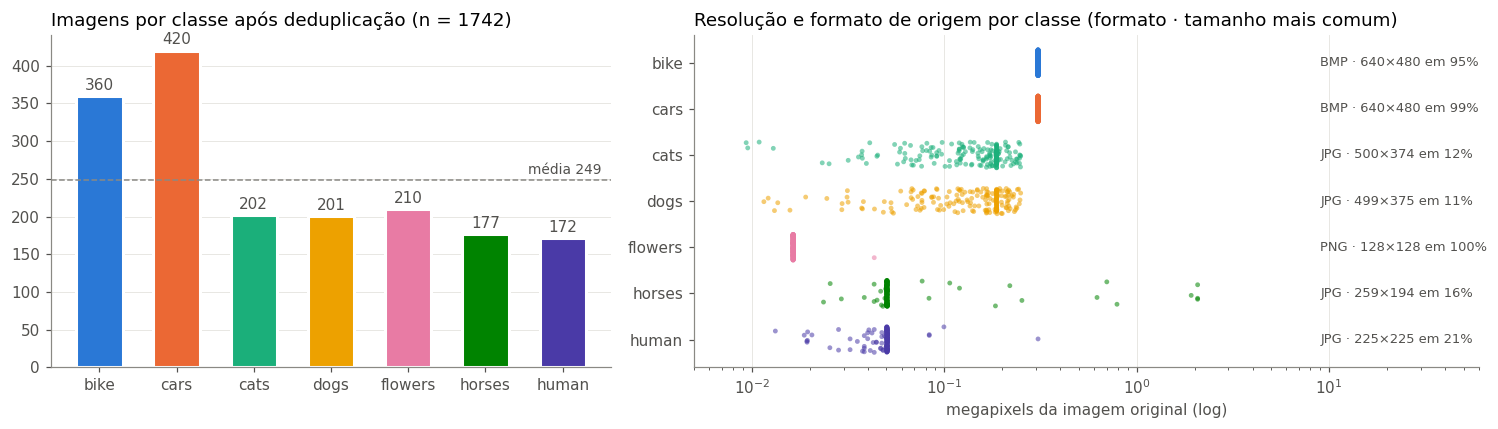

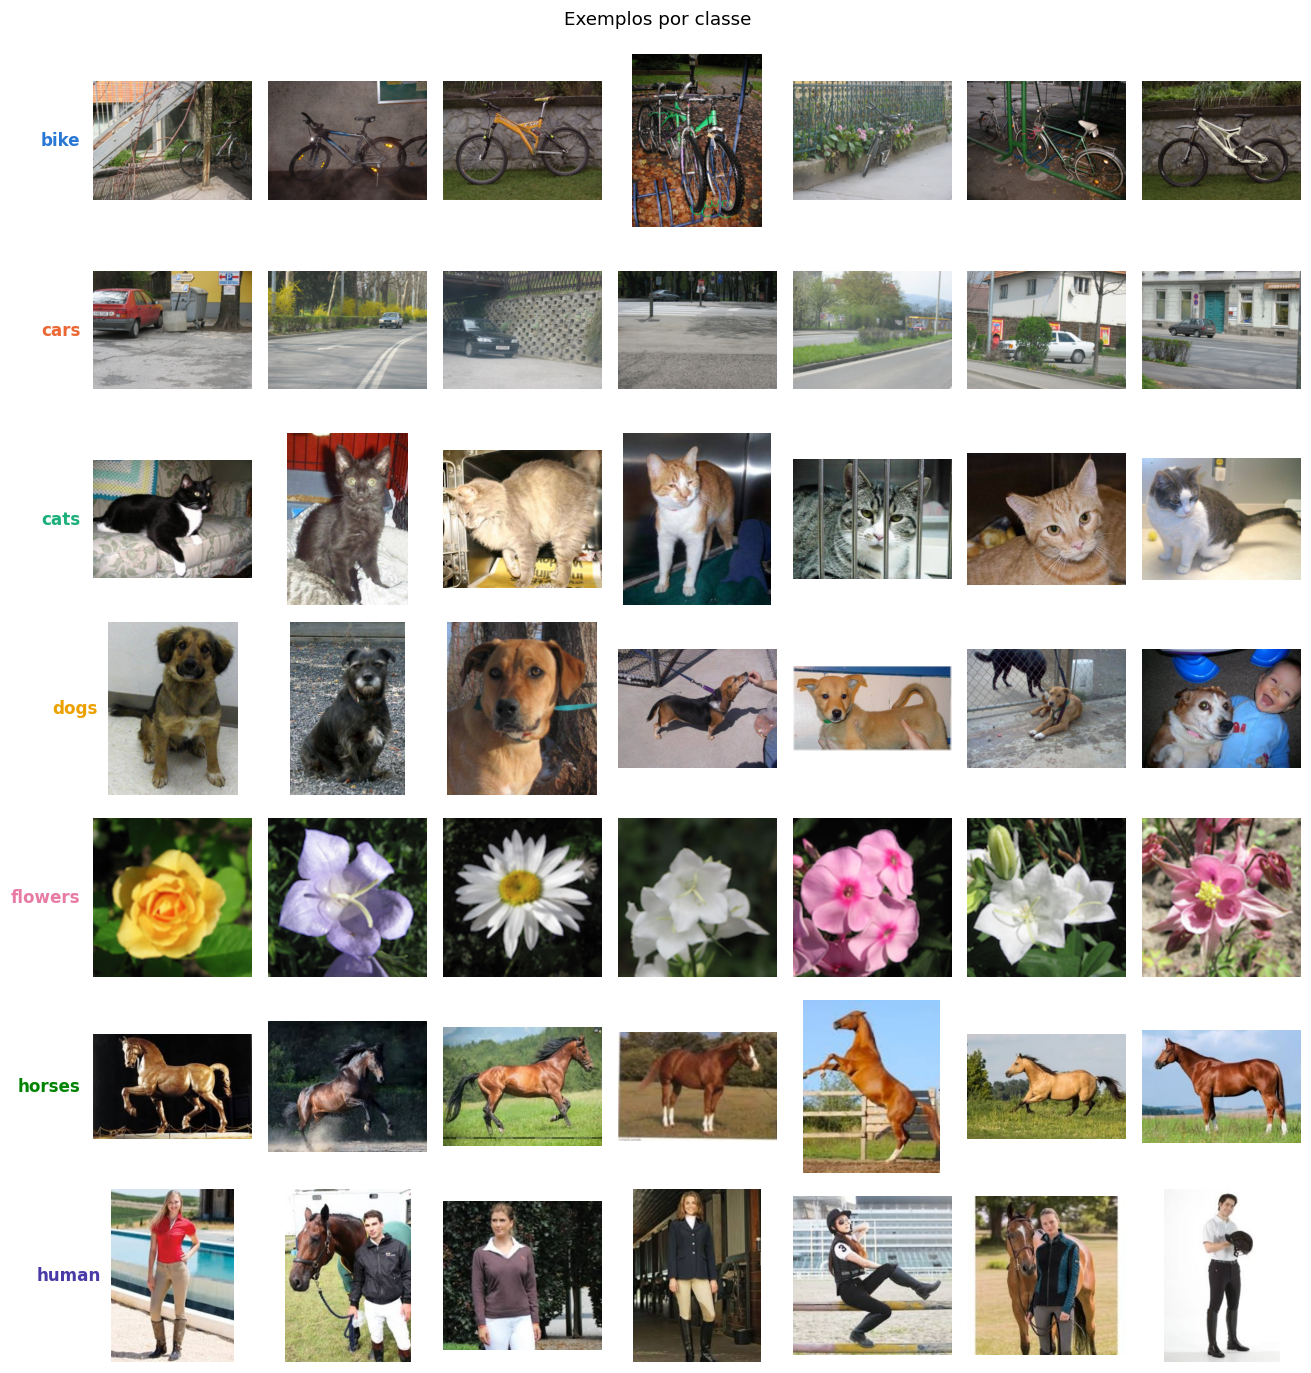

In [6]:
# EDA: distribuição de classes, exemplos e resolução de origem por classe
counts = df.cls.value_counts().reindex(CLASSES)
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.4]})
bars = ax[0].bar(CLASSES, counts.values, color=[PALETTE[i] for i in range(NC)], width=0.6, edgecolor="white", lw=2)
ax[0].bar_label(bars, padding=2, color="#52514e")
ax[0].axhline(counts.mean(), color="#8a8984", ls="--", lw=1)
ax[0].text(NC - 0.5, counts.mean() + 8, f"média {counts.mean():.0f}", ha="right", color="#52514e", fontsize=9)
ax[0].set_title(f"Imagens por classe após deduplicação (n = {len(df)})", loc="left")
ax[0].grid(axis="x", visible=False)
jit = np.random.default_rng(0)
for i, c in enumerate(CLASSES):
    d = df[df.cls == c]
    mpx = d.w * d.h / 1e6
    ax[1].scatter(mpx, i + jit.uniform(-0.28, 0.28, len(d)), s=10, alpha=0.55, color=PALETTE[i],
                  edgecolors="none")
    fmt = "/".join(sorted(set(d.fmt))).replace(".", "").upper()
    sizes = d.groupby(["w", "h"]).size().sort_values(ascending=False)
    top = f"{sizes.index[0][0]}×{sizes.index[0][1]} em {sizes.iloc[0] / len(d):.0%}"
    ax[1].text(9, i, f"{fmt} · {top}", va="center", fontsize=8.5, color="#52514e")
ax[1].set_xscale("log"); ax[1].set_xlim(0.005, 60)
ax[1].set_yticks(range(NC), CLASSES); ax[1].invert_yaxis(); ax[1].grid(axis="y", visible=False)
ax[1].set_xlabel("megapixels da imagem original (log)")
ax[1].set_title("Resolução e formato de origem por classe (formato · tamanho mais comum)", loc="left")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_classes_resolucao.png"); plt.show()

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(NC, 7, figsize=(12, 12.5))
for i, c in enumerate(CLASSES):
    ids = rng.choice(np.where(y == i)[0], 7, replace=False)
    for j, k in enumerate(ids):
        axes[i, j].imshow(IMGS[k]); axes[i, j].axis("off")
    axes[i, 0].text(-0.08, 0.5, c, transform=axes[i, 0].transAxes, ha="right", va="center", fontsize=11,
                    color=PALETTE[i], fontweight="bold")
plt.suptitle("Exemplos por classe", y=0.995)
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_amostras.png"); plt.show()

**O que as amostras mostram** (e que orienta as decisões do §3.2):

- `bike` e `cars` são **cenas de rua**: o objeto nem sempre está centrado e, em `cars`, às vezes ocupa uma fração
  pequena da imagem (carro estacionado ao fundo, atrás de grama ou árvores). Crops agressivos podem cortá-lo fora.
- `human` são quase todos **cavaleiros/amazonas em traje de equitação**, várias vezes com cavalo na foto. Já `horses`
  às vezes tem pessoas. Esse é o par com maior risco de confusão semântica.
- `cats` e `dogs` são fotos amadoras de pets, com fundo doméstico e às vezes com pessoas.
- `flowers` são close-ups centrados e saturados, de baixa resolução: a cor é a pista mais forte da classe.
- `human` tem uma fração alta de fotos em tons de cinza/sépia (fotos antigas), coisa rara nas outras classes.

## 2. Escolha do modelo pré-treinado

Candidatos compatíveis com a T4 (16 GB): **ResNet-50** e **EfficientNet-B0**. Os números abaixo vêm dos metadados
oficiais dos pesos do torchvision; a vazão e a memória são medidas aqui, no hardware da execução.

In [7]:
CANDIDATES = {
    "ResNet-50": (models.resnet50, models.ResNet50_Weights.IMAGENET1K_V2),
    "EfficientNet-B0": (models.efficientnet_b0, models.EfficientNet_B0_Weights.IMAGENET1K_V1),
}


@torch.inference_mode()
def throughput(net, bs=64, reps=3):
    x = torch.randn(bs, 3, 224, 224, device=device)
    net(x[:8])
    if device == "cuda":
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t = time.time()
    for _ in range(reps):
        net(x)
    if device == "cuda":
        torch.cuda.synchronize()
    vram = torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else float("nan")
    return bs * reps / (time.time() - t), vram


rows = []
for name, (fn, w) in CANDIDATES.items():
    net = fn(weights=w).eval().to(device)
    ips, vram = throughput(net)
    feat_dim = net.fc.in_features if hasattr(net, "fc") else net.classifier[-1].in_features
    m = w.meta
    rows.append({"modelo": name, "parâmetros (M)": m["num_params"] / 1e6, "GFLOPs": m["_ops"],
                 "ImageNet top-1 (%)": m["_metrics"]["ImageNet-1K"]["acc@1"], "dim. features": feat_dim,
                 "img/s (inferência, batch 64)": ips, "VRAM batch 64 (GB)": vram})
    del net
model_tab = pd.DataFrame(rows).set_index("modelo").round(2)
display(model_tab)
RESULTS["modelos"] = model_tab.reset_index().to_dict(orient="records")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 201MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 200MB/s]


,parâmetros (M),GFLOPs,ImageNet top-1 (%),dim. features,"img/s (inferência, batch 64)",VRAM batch 64 (GB)
modelo,,,,,,
ResNet-50,25.56,4.09,80.86,2048,286.18,0.82
EfficientNet-B0,5.29,0.39,77.69,1280,751.11,0.74


**Decisão: ResNet-50 (`IMAGENET1K_V2`) como modelo principal**, com EfficientNet-B0 como comparação no §4.

- **Domínio.** As 7 classes são objetos do cotidiano, o mesmo tipo de conteúdo do ImageNet, que tem dezenas de classes
  de raças de cães e gatos, `mountain bike`, `sports car`, `daisy`, `sorrel` etc. (confirmado no §3.1, decodificando as
  predições ImageNet originais). Com essa sobreposição, as features de alto nível do ImageNet já separam as classes, e
  o que importa é a **qualidade da representação** congelada: a ResNet-50 V2 tem o maior top-1 dos dois.
- **Colab T4.** Em feature extraction não há backward pelo backbone: só uma passada de inferência por imagem, sem
  gradientes nem estados do otimizador. Medido na T4: a ResNet-50 ocupa **0,82 GB** de VRAM com batch 64 (15 GB
  disponíveis) e processa ~290 imagens/s. Os 10× mais FLOPs que a B0 custam ~3 s a mais na extração das ~1,7 mil
  imagens.
- **Número de classes.** Com 7 classes, o head é um `Linear(2048, 7)`: **14.343 parâmetros** treináveis para ~1.200
  imagens de treino, ou seja, ~12 parâmetros por exemplo. Isso é pouco para um head linear e o overfitting é
  controlável. Com 7 classes não há pressão por um head maior nem por um backbone maior.
- **Por que não a EfficientNet-B0?** É 5× menor e mais rápida, a escolha certa se o alvo fosse edge/mobile ou
  fine-tuning completo com pouca memória. Aqui o gargalo não é computação, e um top-1 maior no ImageNet tende a
  transferir melhor como feature congelada (Kornblith et al., 2019). Isso foi verificado no §4: a B0 erra 4 imagens
  de test, contra 2 da ResNet-50.

## 3.1 Feature extraction: backbone congelado + novo classification head

Protocolo:

1. Carregar a ResNet-50 pré-treinada, **congelar todos os parâmetros** (`requires_grad = False`) e manter o backbone em
   `eval()` (BatchNorm usa as estatísticas do ImageNet, sem atualização).
2. **Substituir** `model.fc` (1000 classes ImageNet) por `nn.Linear(2048, 7)`, a única camada treinável.
3. Pré-processamento padrão dos pesos: `Resize(256) → CenterCrop(224) → Normalize(média/desvio do ImageNet)`.
4. **Um treino** do head: AdamW (lr 1e-3, weight decay 1e-4), cosine schedule, 40 epochs, batch 64, cross-entropy.
   O checkpoint escolhido é o de **menor loss de validação**.

Como o backbone está congelado e sem augmentation, a saída do backbone para cada imagem é sempre a mesma. Por isso a
passada pelo backbone é feita **uma única vez** e as features (2048-d após o global average pool) ficam em cache. Treinar
o `fc` sobre o cache é matematicamente idêntico a treinar o modelo inteiro com o backbone congelado, só que ~40× mais
rápido. A célula de verificação mais abaixo confirma a equivalência no modelo completo.

In [8]:
t0 = time.time()
W_R50 = models.ResNet50_Weights.IMAGENET1K_V2
model = models.resnet50(weights=W_R50)
imagenet_fc = copy.deepcopy(model.fc)              # guardado só para decodificar classes ImageNet (§3.1)

for p in model.parameters():                        # 1) congela o backbone inteiro
    p.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, NC)      # 2) novo head (requires_grad=True por padrão)
model = model.to(device).eval()

n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"parâmetros: total {n_total:,} | treináveis {n_train:,} ({100 * n_train / n_total:.3f}%)")
print("treináveis:", [n for n, p in model.named_parameters() if p.requires_grad])
RESULTS["params_total"], RESULTS["params_treinaveis"] = n_total, n_train

backbone = nn.Sequential(*list(model.children())[:-1], nn.Flatten()).eval()   # tudo menos o fc (mesmos pesos)

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)                       # estatísticas do ImageNet
EVAL_TF = T.Compose([T.CenterCrop(224), T.ToTensor(), T.Normalize(MEAN, STD)])  # imagens já estão em lado menor 256


class ImgDS(Dataset):
    def __init__(self, ids, tf):
        self.ids, self.tf = list(ids), tf
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        return self.tf(IMGS[self.ids[i]])


@torch.inference_mode()
def extract(net, ids, tf, bs=64, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    torch.manual_seed(seed)
    dl = DataLoader(ImgDS(ids, tf), batch_size=bs, shuffle=False, num_workers=NUM_WORKERS, generator=g)
    return torch.cat([net(x.to(device)).float().cpu() for x in dl])


FEAT = {s: extract(backbone, ids, EVAL_TF) for s, ids in [("train", tr), ("val", va), ("test", te)]}
Y = {s: torch.from_numpy(y[ids]) for s, ids in [("train", tr), ("val", va), ("test", te)]}
print({s: tuple(v.shape) for s, v in FEAT.items()})
TIMES["3_1_extracao_r50"] = time.time() - t0

parâmetros: total 23,522,375 | treináveis 14,343 (0.061%)
treináveis: ['fc.weight', 'fc.bias']
{'train': (1219, 2048), 'val': (261, 2048), 'test': (262, 2048)}


In [9]:
def train_head(Ftr, ytr, Fva, yva, epochs=40, lr=1e-3, wd=1e-4, bs=64, seed=SEED, verbose=False):
    set_seed(seed)
    head = nn.Linear(Ftr.shape[1], NC).to(device)
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    Ftr, ytr, Fva, yva = Ftr.to(device), ytr.to(device), Fva.to(device), yva.to(device)
    hist, best, best_loss = [], None, float("inf")
    for ep in range(1, epochs + 1):
        head.train()
        perm = torch.randperm(len(ytr), device=device)
        tl, tc = 0.0, 0
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            out = head(Ftr[b]); loss = F.cross_entropy(out, ytr[b])
            opt.zero_grad(); loss.backward(); opt.step()
            tl += loss.item() * len(b); tc += (out.argmax(1) == ytr[b]).sum().item()
        sched.step()
        head.eval()
        with torch.no_grad():
            out = head(Fva); vl = F.cross_entropy(out, yva).item(); vc = (out.argmax(1) == yva).float().mean().item()
        hist.append(dict(epoch=ep, train_loss=tl / len(ytr), train_acc=tc / len(ytr), val_loss=vl, val_acc=vc))
        if vl < best_loss:
            best_loss, best, best_ep = vl, copy.deepcopy(head.state_dict()), ep
        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"ep {ep:2d} | train loss {tl / len(ytr):.4f} acc {tc / len(ytr):.4f} | val loss {vl:.4f} acc {vc:.4f}")
    head.load_state_dict(best)
    return head.eval(), pd.DataFrame(hist), best_ep


@torch.no_grad()
def predict(head, Fx):
    return torch.softmax(head(Fx.to(device)), 1).cpu().numpy()


def metrics(y_true, prob):
    pred = prob.argmax(1)
    cm = confusion_matrix(y_true, pred, labels=range(NC))
    return {"accuracy": accuracy_score(y_true, pred), "balanced_acc": balanced_accuracy_score(y_true, pred),
            "f1_macro": f1_score(y_true, pred, average="macro"),
            "acc_por_classe": dict(zip(CLASSES, (cm.diagonal() / cm.sum(1)).tolist())), "cm": cm}


t0 = time.time()
head, hist, best_ep = train_head(FEAT["train"], Y["train"], FEAT["val"], Y["val"], verbose=True)
print("melhor epoch (menor val loss):", best_ep)
model.fc.load_state_dict(head.state_dict())        # o head treinado vira o fc do modelo completo
TIMES["3_1_treino_head"] = time.time() - t0
RESULTS["historico"] = hist.round(5).to_dict(orient="list"); RESULTS["melhor_epoch"] = best_ep

ep  1 | train loss 1.1712 acc 0.8326 | val loss 0.5656 acc 0.9885
ep  5 | train loss 0.0918 acc 0.9984 | val loss 0.0992 acc 0.9923
ep 10 | train loss 0.0392 acc 0.9992 | val loss 0.0540 acc 0.9923
ep 15 | train loss 0.0242 acc 0.9992 | val loss 0.0396 acc 0.9923
ep 20 | train loss 0.0179 acc 1.0000 | val loss 0.0334 acc 0.9923
ep 25 | train loss 0.0147 acc 1.0000 | val loss 0.0304 acc 0.9923
ep 30 | train loss 0.0132 acc 1.0000 | val loss 0.0290 acc 0.9923
ep 35 | train loss 0.0126 acc 1.0000 | val loss 0.0284 acc 0.9923
ep 40 | train loss 0.0124 acc 1.0000 | val loss 0.0283 acc 0.9923
melhor epoch (menor val loss): 40


In [10]:
# Verificação: o MODELO COMPLETO (backbone congelado + fc treinado) aplicado a imagens cruas dá as mesmas
# probabilidades que o head aplicado às features em cache.
xb = torch.stack([EVAL_TF(IMGS[k]) for k in te[:32]]).to(device)
with torch.inference_mode():
    p_full = torch.softmax(model(xb), 1).cpu().numpy()
p_cache = predict(head, FEAT["test"][:32])
print("max |Δprob| modelo completo vs. cache:", float(np.abs(p_full - p_cache).max()))
assert np.allclose(p_full, p_cache, atol=1e-4)

max |Δprob| modelo completo vs. cache: 2.384185791015625e-07


### Curvas de loss e accuracy por epoch

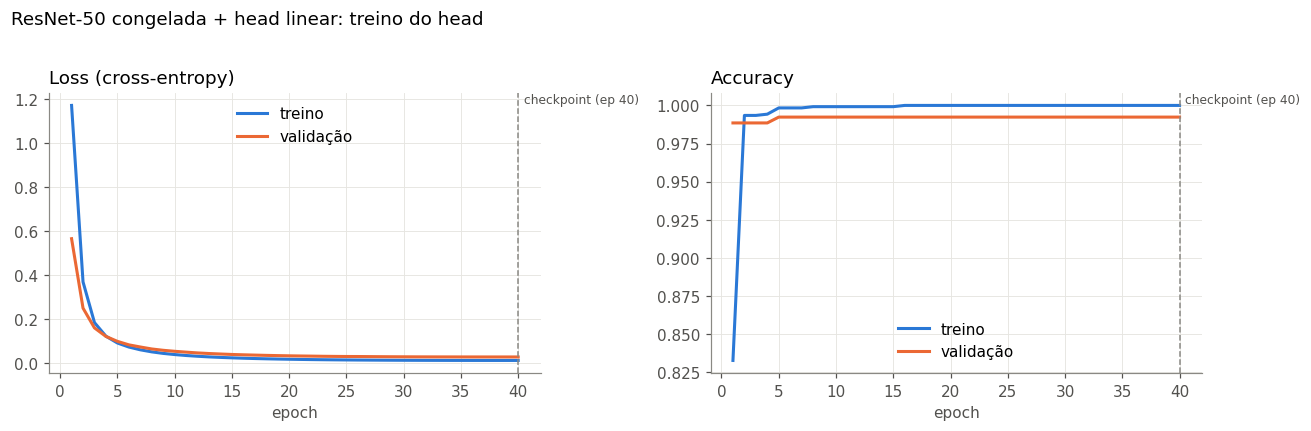

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, (col_tr, col_va, title) in enumerate([("train_loss", "val_loss", "Loss (cross-entropy)"),
                                              ("train_acc", "val_acc", "Accuracy")]):
    ax[k].plot(hist.epoch, hist[col_tr], color=PALETTE[0], lw=2, label="treino")
    ax[k].plot(hist.epoch, hist[col_va], color=PALETTE[1], lw=2, label="validação")
    ax[k].axvline(best_ep, color="#8a8984", ls="--", lw=1)
    ax[k].text(best_ep + 0.5, ax[k].get_ylim()[1], f"checkpoint (ep {best_ep})", va="top", fontsize=8,
               color="#52514e")
    ax[k].set_xlabel("epoch"); ax[k].set_title(title, loc="left"); ax[k].legend(frameon=False)
plt.suptitle("ResNet-50 congelada + head linear: treino do head", x=0.01, ha="left", y=1.02)
plt.tight_layout(); plt.savefig(FIG_DIR / "curvas_treino.png"); plt.show()

### Accuracy global, accuracy por classe e matriz de confusão (test)

In [12]:
P_TEST = predict(head, FEAT["test"])
M = metrics(Y["test"].numpy(), P_TEST)
M_VAL = metrics(Y["val"].numpy(), predict(head, FEAT["val"]))
print(f"TEST  accuracy {M['accuracy']:.4f} | balanced acc {M['balanced_acc']:.4f} | F1 macro {M['f1_macro']:.4f}")
print(f"VAL   accuracy {M_VAL['accuracy']:.4f} | balanced acc {M_VAL['balanced_acc']:.4f}")

per_class = pd.DataFrame({"n test": np.bincount(Y["test"].numpy(), minlength=NC),
                          "acc val": list(M_VAL["acc_por_classe"].values()),
                          "acc test": list(M["acc_por_classe"].values()),
                          "erros test": M["cm"].sum(1) - M["cm"].diagonal()}, index=CLASSES)
per_class.loc["GLOBAL"] = [per_class["n test"].sum(), M_VAL["accuracy"], M["accuracy"], per_class["erros test"].sum()]
display(per_class.style.format({"acc val": "{:.3f}", "acc test": "{:.3f}"}))
print(classification_report(Y["test"].numpy(), P_TEST.argmax(1), target_names=CLASSES, digits=3))

# robustez à seed do head (inicialização + ordem dos batches): mesmo protocolo, 5 seeds
seed_rows = []
for s in [42, 1, 2, 3, 4]:
    h, _, _ = train_head(FEAT["train"], Y["train"], FEAT["val"], Y["val"], seed=s)
    ms = metrics(Y["test"].numpy(), predict(h, FEAT["test"]))
    seed_rows.append({"seed": s, "accuracy": ms["accuracy"], "f1_macro": ms["f1_macro"], **ms["acc_por_classe"]})
seed_df = pd.DataFrame(seed_rows).set_index("seed")
print("test, 5 seeds do head (média ± desvio):")
display(seed_df.agg(["mean", "std"]).T.round(4))

RESULTS["test"] = {k: v for k, v in M.items() if k != "cm"}
RESULTS["val"] = {k: v for k, v in M_VAL.items() if k != "cm"}
RESULTS["cm_test"] = M["cm"].tolist()
RESULTS["seeds"] = seed_df.agg(["mean", "std"]).to_dict()

TEST  accuracy 0.9924 | balanced acc 0.9951 | F1 macro 0.9951
VAL   accuracy 0.9923 | balanced acc 0.9899


,n test,acc val,acc test,erros test
bike,54.000000,1.000,0.981,1.000000
cars,63.000000,1.000,0.984,1.000000
cats,31.000000,0.967,1.000,0.000000
dogs,30.000000,1.000,1.000,0.000000
flowers,32.000000,1.000,1.000,0.000000
horses,26.000000,0.963,1.000,0.000000
human,26.000000,1.000,1.000,0.000000
GLOBAL,262.000000,0.992,0.992,2.000000


              precision    recall  f1-score   support

        bike      0.981     0.981     0.981        54
        cars      0.984     0.984     0.984        63
        cats      1.000     1.000     1.000        31
        dogs      1.000     1.000     1.000        30
     flowers      1.000     1.000     1.000        32
      horses      1.000     1.000     1.000        26
       human      1.000     1.000     1.000        26

    accuracy                          0.992       262
   macro avg      0.995     0.995     0.995       262
weighted avg      0.992     0.992     0.992       262

test, 5 seeds do head (média ± desvio):


,mean,std
accuracy,0.9924,0.0
f1_macro,0.9951,0.0
bike,0.9815,0.0
cars,0.9841,0.0
cats,1.0000,0.0
dogs,1.0000,0.0
flowers,1.0000,0.0
horses,1.0000,0.0
human,1.0000,0.0


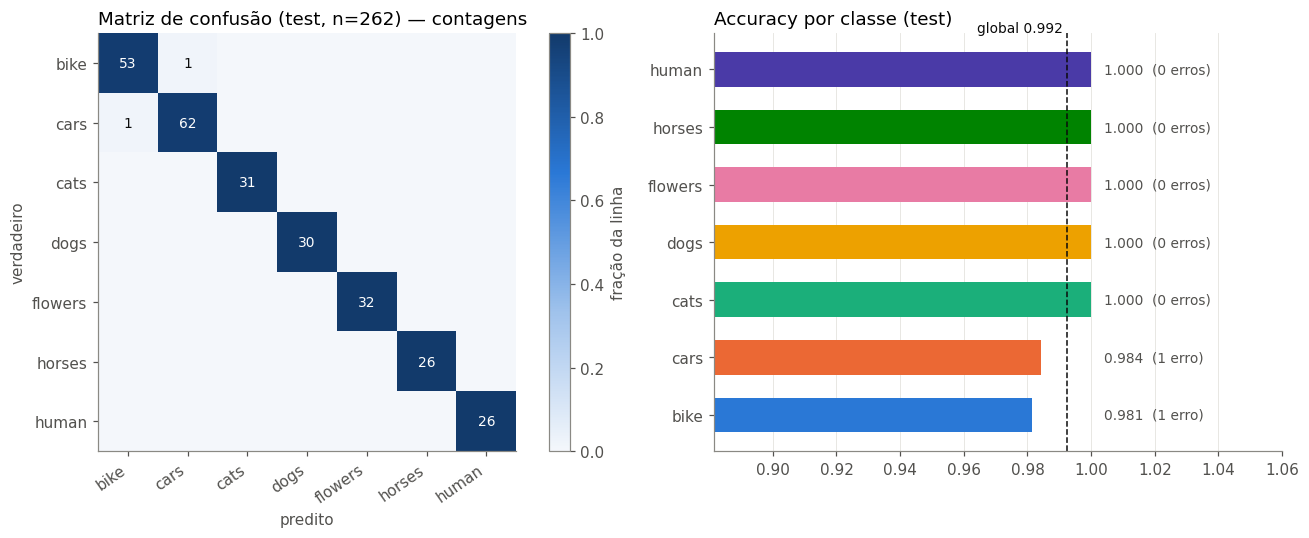

In [13]:
cm = M["cm"]; cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.15, 1]})
im = ax[0].imshow(cmn, cmap=SEQ, vmin=0, vmax=1)
for i in range(NC):
    for j in range(NC):
        if cm[i, j]:
            ax[0].text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=9,
                       color="white" if cmn[i, j] > 0.55 else "#0b0b0b")
ax[0].set_xticks(range(NC), CLASSES, rotation=35, ha="right"); ax[0].set_yticks(range(NC), CLASSES)
ax[0].set_xlabel("predito"); ax[0].set_ylabel("verdadeiro"); ax[0].grid(False)
ax[0].set_title(f"Matriz de confusão (test, n={len(te)}) — contagens", loc="left")
plt.colorbar(im, ax=ax[0], fraction=0.046, label="fração da linha")

acc_c = np.array(list(M["acc_por_classe"].values()))
order = np.argsort(acc_c)
ax[1].barh([CLASSES[i] for i in order], acc_c[order], color=[PALETTE[i] for i in order], height=0.6)
for k, i in enumerate(order):
    ax[1].text(1.004, k, f"{acc_c[i]:.3f}  ({cm[i].sum() - cm[i, i]} erro{'s' if cm[i].sum() - cm[i, i] != 1 else ''})",
               va="center", fontsize=9, color="#52514e")
ax[1].axvline(M["accuracy"], color="#0b0b0b", ls="--", lw=1)
ax[1].text(M["accuracy"], NC - 0.35, f"global {M['accuracy']:.3f} ", fontsize=9, color="#0b0b0b", ha="right")
ax[1].set_xlim(max(0, acc_c.min() - 0.1), 1.06); ax[1].set_title("Accuracy por classe (test)", loc="left")
ax[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "confusao_por_classe.png"); plt.show()

### O que o backbone já "sabe": predições ImageNet originais e geometria das features

Duas checagens que ajudam a explicar o resultado e justificam a escolha de feature extraction:

1. aplicar o **head ImageNet original** (1000 classes) às mesmas features e ver as classes ImageNet mais previstas
   para cada uma das 7 classes, ou seja, quanto do nosso domínio já está no vocabulário do ImageNet;
2. projetar as features 2048-d em 2D com **t-SNE** para ver se as classes já formam grupos separados *antes* de
   qualquer treino.

,top-3 classes ImageNet (fração das imagens),nº de classes ImageNet distintas
classe,,
bike,mountain bike (45%) · bicycle-built-for-two (29%) · tricycle (8%),30
cars,beach wagon (18%) · minivan (16%) · cab (8%),73
cats,Egyptian cat (32%) · tabby (30%) · tiger cat (9%),24
dogs,American Staffordshire terrier (10%) · Labrador retriever (7%) · kelpie (5%),68
flowers,daisy (36%) · pot (20%) · earthstar (8%),22
horses,sorrel (71%) · Saluki (9%) · Great Dane (4%),24
human,suit (17%) · sorrel (10%) · Windsor tie (8%),48


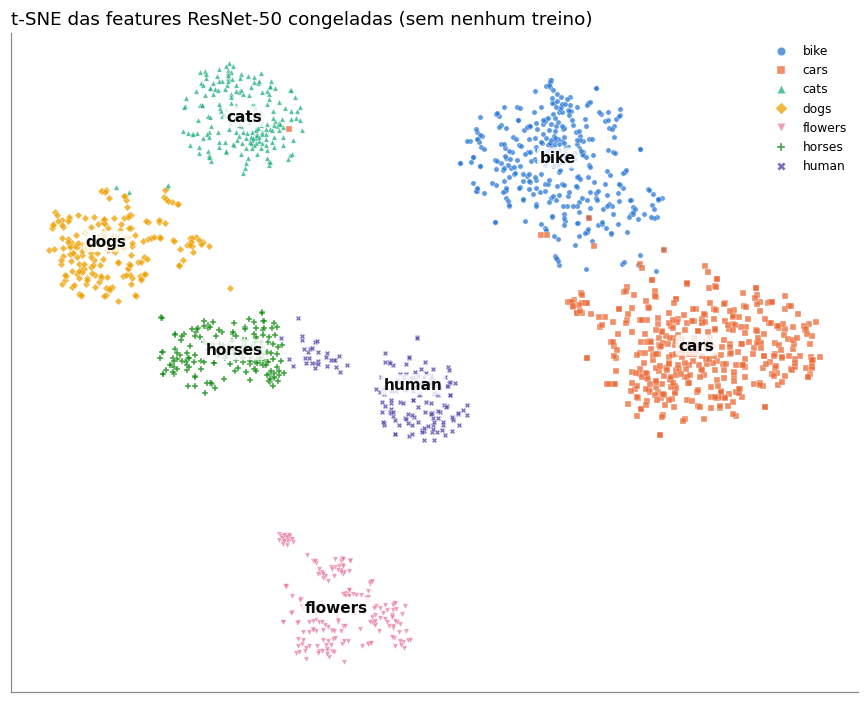

In [14]:
in_names = W_R50.meta["categories"]
with torch.no_grad():
    in_pred = imagenet_fc.to(device)(torch.cat([FEAT["train"], FEAT["val"], FEAT["test"]]).to(device)).argmax(1).cpu()
y_all = torch.cat([Y["train"], Y["val"], Y["test"]])
rows = []
for i, c in enumerate(CLASSES):
    vc = pd.Series([in_names[k] for k in in_pred[y_all == i].tolist()]).value_counts()
    rows.append({"classe": c, "top-3 classes ImageNet (fração das imagens)":
                 " · ".join(f"{n} ({v / vc.sum():.0%})" for n, v in vc.head(3).items()),
                 "nº de classes ImageNet distintas": len(vc)})
in_tab = pd.DataFrame(rows).set_index("classe")
pd.set_option("display.max_colwidth", 120)
display(in_tab)
RESULTS["imagenet_top3"] = in_tab.reset_index().to_dict(orient="records")

t0 = time.time()
Z = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(
    torch.cat([FEAT["train"], FEAT["val"], FEAT["test"]]).numpy())
fig, ax = plt.subplots(figsize=(8, 6.5))
for i, c in enumerate(CLASSES):
    m_ = (y_all == i).numpy()
    ax.scatter(Z[m_, 0], Z[m_, 1], s=12, color=PALETTE[i], marker=MARKERS[i], alpha=0.75, label=c,
               edgecolors="white", lw=0.3)
    cx, cy = np.median(Z[m_], 0)
    ax.text(cx, cy, c, fontsize=10, fontweight="bold", color="#0b0b0b", ha="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.legend(frameon=False, fontsize=8, markerscale=1.6, loc="best")
ax.set_title("t-SNE das features ResNet-50 congeladas (sem nenhum treino)", loc="left")
plt.tight_layout(); plt.savefig(FIG_DIR / "tsne_features.png"); plt.show()
TIMES["3_1_tsne"] = time.time() - t0

### Erros do modelo, vazamento residual e auditoria de rótulos

- **Erros:** todas as imagens de test classificadas errado, com a confiança do modelo.
- **Vazamento residual:** mesmo após a deduplicação por hash, checo no espaço de features se alguma imagem de test tem
  um "quase-gêmeo" no treino (similaridade de cosseno ≥ 0,95) e recalculo a accuracy sem esses casos.
- **Rótulos:** com 7 classes muito bem separadas, uma imagem cercada de vizinhos de outra classe é suspeita de rótulo
  errado ou de conteúdo ambíguo (ex.: cavaleiro com cavalo).

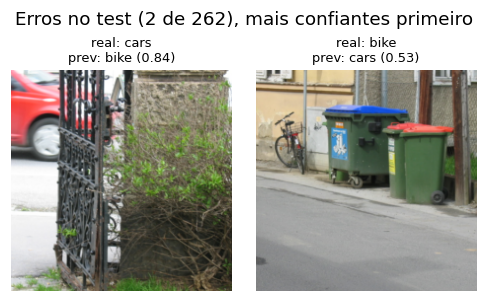

test com vizinho de treino de cosseno ≥ 0.9: 11
test com vizinho de treino de cosseno ≥ 0.95: 2
test com vizinho de treino de cosseno ≥ 0.98: 0
accuracy de test sem esses casos: 0.9923 (com: 0.9924)


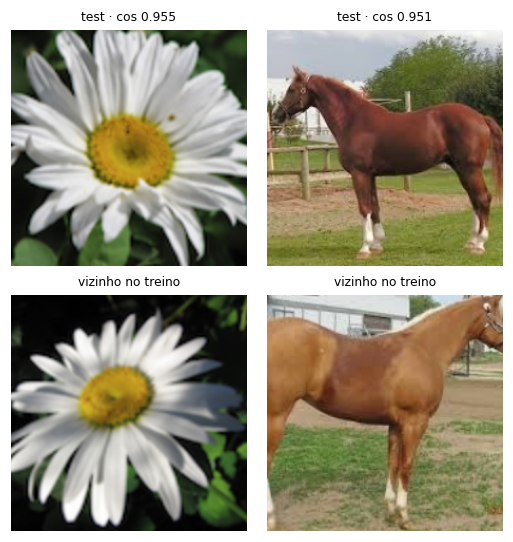

In [15]:
# galeria de todos os erros de test (até 12), com a probabilidade da classe prevista
pred = P_TEST.argmax(1); yt = Y["test"].numpy()
err = np.where(pred != yt)[0]
err = err[np.argsort(-P_TEST[err, pred[err]])][:12]
if len(err):
    ncol = min(6, len(err)); nrow = int(np.ceil(len(err) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.3 * ncol, 2.7 * nrow), squeeze=False)
    for a in axes.ravel():
        a.axis("off")
    for a, k in zip(axes.ravel(), err):
        a.imshow(TF.center_crop(IMGS[te[k]], 224))
        a.set_title(f"real: {CLASSES[yt[k]]}\nprev: {CLASSES[pred[k]]} ({P_TEST[k, pred[k]]:.2f})", fontsize=8.5)
    plt.suptitle(f"Erros no test ({(pred != yt).sum()} de {len(yt)}), mais confiantes primeiro", y=1.0)
    plt.tight_layout(); plt.savefig(FIG_DIR / "erros_test.png"); plt.show()

# vazamento: para cada imagem de test, a maior similaridade de cosseno com qualquer imagem de treino
Ftr_n, Fte_n = F.normalize(FEAT["train"], dim=1), F.normalize(FEAT["test"], dim=1)
sim = Fte_n @ Ftr_n.T
max_sim, nn_idx = sim.max(1)
for th in [0.90, 0.95, 0.98]:
    print(f"test com vizinho de treino de cosseno ≥ {th}: {(max_sim >= th).sum().item()}")
near = (max_sim >= 0.95).numpy()
if near.any():
    acc_clean = (pred[~near] == yt[~near]).mean()
    print(f"accuracy de test sem esses casos: {acc_clean:.4f} (com: {M['accuracy']:.4f})")
    show = np.where(near)[0][np.argsort(-max_sim[near].numpy())][:5]
    fig, axes = plt.subplots(2, len(show), figsize=(2.4 * len(show), 5), squeeze=False)
    for j, k in enumerate(show):
        axes[0, j].imshow(TF.center_crop(IMGS[te[k]], 224)); axes[0, j].set_title(f"test · cos {max_sim[k]:.3f}", fontsize=8)
        axes[1, j].imshow(TF.center_crop(IMGS[tr[nn_idx[k]]], 224)); axes[1, j].set_title("vizinho no treino", fontsize=8)
        axes[0, j].axis("off"); axes[1, j].axis("off")
    plt.tight_layout(); plt.savefig(FIG_DIR / "near_duplicates.png"); plt.show()
RESULTS["near_dup_test_095"] = int(near.sum())
RESULTS["acc_test_sem_near_dup"] = float((pred[~near] == yt[~near]).mean())

imagens com ≥7 de 10 vizinhos de outra classe: 8 de 1742


,arquivo,rótulo,maioria dos vizinhos,discordância,split
0,bike_097.bmp,bike,cars,0.9,train
1,rider-79.jpg,human,horses,0.9,train
2,bike_050.bmp,bike,cars,0.9,test
3,bike_095.bmp,bike,cars,0.8,train
4,bike_034.bmp,bike,cars,0.8,train
5,cat.44.jpg,cats,human,0.8,train
6,bike_047.bmp,bike,cars,0.7,train
7,carsgraz_152.bmp,cars,bike,0.7,test


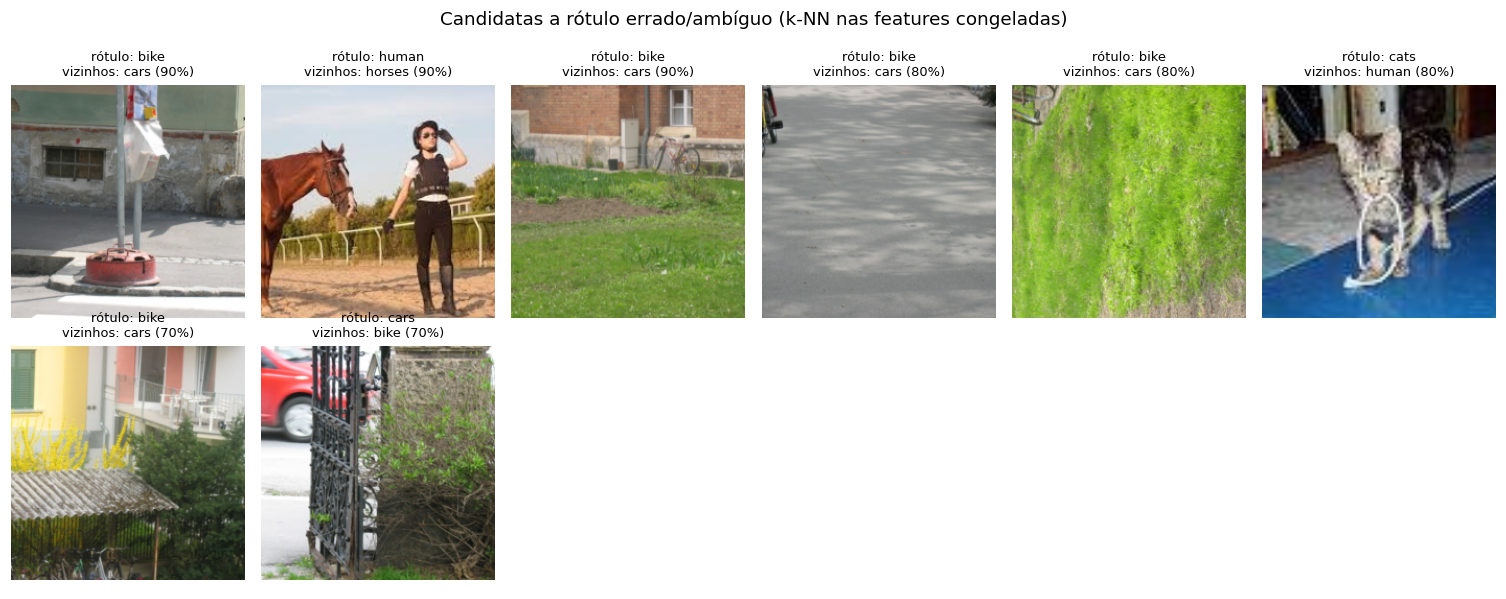

In [16]:
# Auditoria de rótulos: imagens cujos 10 vizinhos mais próximos (cosseno, features congeladas) são
# majoritariamente de OUTRA classe. Candidatas a rótulo errado ou a imagem ambígua.
ids_all = np.concatenate([tr, va, te]); split_of = np.array(["train"] * len(tr) + ["val"] * len(va) + ["test"] * len(te))
Fa = F.normalize(torch.cat([FEAT["train"], FEAT["val"], FEAT["test"]]), dim=1)
S_ = Fa @ Fa.T; S_.fill_diagonal_(-1)
knn = S_.topk(10, dim=1).indices.numpy()
ya = y_all.numpy()
disagree = (ya[knn] != ya[:, None]).mean(1)
maj = np.array([np.bincount(ya[k], minlength=NC).argmax() for k in knn])
sus = np.where(disagree >= 0.7)[0]
sus = sus[np.argsort(-disagree[sus])]
print(f"imagens com ≥7 de 10 vizinhos de outra classe: {len(sus)} de {len(ya)}")
sus_tab = pd.DataFrame({"arquivo": [Path(df.path[ids_all[k]]).name for k in sus], "rótulo": [CLASSES[ya[k]] for k in sus],
                        "maioria dos vizinhos": [CLASSES[maj[k]] for k in sus], "discordância": disagree[sus],
                        "split": split_of[sus]})
display(sus_tab)
RESULTS["suspeitas_rotulo"] = sus_tab.to_dict(orient="records")
if len(sus):
    show = sus[:12]; ncol = min(6, len(show)); nrow = int(np.ceil(len(show) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.3 * ncol, 2.7 * nrow), squeeze=False)
    for a in axes.ravel():
        a.axis("off")
    for a, k in zip(axes.ravel(), show):
        a.imshow(TF.center_crop(IMGS[ids_all[k]], 224))
        a.set_title(f"rótulo: {CLASSES[ya[k]]}\nvizinhos: {CLASSES[maj[k]]} ({disagree[k]:.0%})", fontsize=8.5)
    plt.suptitle("Candidatas a rótulo errado/ambíguo (k-NN nas features congeladas)", y=1.0)
    plt.tight_layout(); plt.savefig(FIG_DIR / "auditoria_rotulos.png"); plt.show()

### Análise dos resultados do §3.1

**Desempenho.** O head linear sobre a ResNet-50 congelada acerta **260 de 262 imagens de test: accuracy 0,992,
balanced accuracy 0,995 e F1 macro 0,995** (validação: 0,992). Cinco classes ficam com accuracy 1,000. Os dois erros
estão em `bike` (0,981) e `cars` (0,984), um em cada.

| Classe | n test | Accuracy val | **Accuracy test** | Erros test |
|---|---|---|---|---|
| bike | 54 | 1,000 | **0,981** | 1 (→ cars) |
| cars | 63 | 1,000 | **0,984** | 1 (→ bike) |
| cats | 31 | 0,967 | **1,000** | 0 |
| dogs | 30 | 1,000 | **1,000** | 0 |
| flowers | 32 | 1,000 | **1,000** | 0 |
| horses | 26 | 0,963 | **1,000** | 0 |
| human | 26 | 1,000 | **1,000** | 0 |
| **Global** | **262** | **0,992** | **0,992** | **2** |

**Curvas.** A accuracy de validação já é 0,989 **no primeiro epoch**: as features do ImageNet já são quase linearmente
separáveis para estas 7 classes, e o head só precisa achar os hiperplanos. A loss de validação cai monotonicamente até
0,028 e nunca sobe, então não há overfitting. O treino chega a 100% no epoch 20, com loss 0,012 contra 0,028 na
validação. Esse gap pequeno é esperado para um modelo de 14 mil parâmetros. O checkpoint de menor val loss é o
**último epoch (40)**, mas as últimas 10 epochs mudam a loss na quarta casa decimal: mais epochs não trariam ganho.

**Robustez à seed: desvio-padrão 0 em 5 seeds.** Não é um bug. Um head linear com cross-entropy e weight decay é uma
regressão logística com regularização L2, um problema **convexo com ótimo único**. Com 40 epochs e cosine schedule,
toda inicialização e toda ordem de batches convergem para a mesma solução. O resultado mede as features, não a sorte
do treino. Isso é uma vantagem prática da feature extraction sobre o fine-tuning, que não é convexo.

**Os dois erros são cenas ambíguas, não falhas grosseiras.** Ambos vêm do Graz-02, onde `bike` e `cars` são cenas de
rua com um único rótulo por imagem:

- carro vermelho parcialmente escondido atrás de um portão de ferro trabalhado, previsto como `bike` com P = 0,83. A
  grade metálica tem a mesma textura de tubos e raios de uma bicicleta;
- bicicleta pequena encostada ao lado de duas lixeiras grandes, prevista como `cars` com P = 0,53, um quase empate.

**O que o backbone já sabe.** Decodificando as predições do head ImageNet original sobre as mesmas features:

- `bike` → *mountain bike* (45%) e *bicycle-built-for-two* (29%);
- `cats` → *Egyptian cat*, *tabby* e *tiger cat*;
- `horses` → *sorrel* (71%);
- `flowers` → *daisy* (36%), além de *pot* (20%, flor em vaso).

A sobreposição de domínio é direta. Duas exceções explicam a estrutura do problema:

- `cars` se espalha por **73 classes ImageNet** (*beach wagon*, *minivan*, *cab*...), porque o carro muitas vezes é
  pequeno na cena;
- `human` **não tem classe "pessoa" no ImageNet**: o backbone reconhece cavaleiros pela roupa (*suit*, *Windsor tie*)
  e pelo contexto (*sorrel*, o cavalo ao lado).

O t-SNE mostra 7 grupos separados **sem nenhum treino**. Há um pequeno satélite de `human` colado em `horses`
(cavaleiros com o cavalo), e `bike` e `cars` são vizinhos.

**Vazamento residual: nenhum.** Depois da deduplicação, nenhuma imagem de test tem vizinho de treino com cosseno
≥ 0,98. As duas com cosseno ≥ 0,95 são fotos diferentes (outra margarida, outro cavalo alazão). Sem elas, a accuracy é
0,9923.

**Auditoria de rótulos: 8 de 1.742 imagens suspeitas**, e a maioria não tem rótulo errado. **Cinco são `bike` em que
a bicicleta está na borda da foto**: depois do `CenterCrop(224)` sobra só grama ou calçada, e os vizinhos são cenas de
rua de `cars`. As outras são um cavaleiro segurando o cavalo (`human` cercado de `horses`), um gato com fundo doméstico
de pessoa e o carro atrás do portão. Lição para o §3.2: em `bike` e `cars`, **recortar a imagem pode remover o objeto
que define o rótulo**.

## 3.2 Análise e propostas de melhoria

O enunciado pede para discutir quais melhorias testar e por quê. Em vez de argumentar só no papel, rodo três
experimentos baratos que **mantêm o backbone congelado** (é o mesmo modelo do §3.1, só muda o que entra no head):

- **§3.2.a — Sensibilidade por classe.** Aplico transformações determinísticas às imagens de *test* (flip, rotação,
  grayscale, mudança de matiz, zoom, baixa resolução...) e meço a accuracy **por classe** do head treinado. Uma queda
  grande indica que a classe depende daquela propriedade da imagem. Logo, (1) essa augmentation pode distorcer a
  classe no treino, ou (2) o modelo é frágil a essa variação e a augmentation tornaria ele mais robusto.
- **§3.2.b — Normalização.** Extraio as features com três normalizações (ImageNet, nenhuma, estatísticas do próprio
  dataset) e treino o mesmo head.
- **§3.2.c — Augmentation no treino do head.** Para cada família (geométrica, cor, escala, combinada) gero 3 vistas
  aumentadas de cada imagem de treino, extraio as features e treino o head com original + vistas. Avalio no test
  limpo **e** no test transformado do §3.2.a, porque a augmentation deve melhorar a robustez, não só a accuracy limpa.

### 3.2.a Sensibilidade por classe a cada transformação (test)

In [17]:
t0 = time.time()


def zoom(im, frac):           # recorte central com `frac` do lado menor (área ≈ frac²), reamostrado a 256
    s = int(min(im.size) * frac)
    return TF.resize(TF.center_crop(im, s), SHORT, antialias=True)


def lowres(im, s=64):         # simula fonte de baixa resolução (como as flores de 128 px)
    return TF.resize(TF.resize(im, s, antialias=True), SHORT, antialias=True)


TO_T = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
PERTURB = {   # nome: transformação PIL -> tensor normalizado 224x224
    "original":            EVAL_TF,
    "flip horizontal":     lambda im: EVAL_TF(TF.hflip(im)),
    "flip vertical":       lambda im: EVAL_TF(TF.vflip(im)),
    "rotação 15°":         lambda im: EVAL_TF(TF.rotate(im, 15)),
    "rotação 90°":         lambda im: EVAL_TF(TF.rotate(im, 90, expand=True)),
    "grayscale":           lambda im: EVAL_TF(TF.to_grayscale(im, 3)),
    "matiz +0,25":         lambda im: EVAL_TF(TF.adjust_hue(im, 0.25)),
    "jitter brilho/contr./sat.": lambda im: EVAL_TF(TF.adjust_saturation(TF.adjust_contrast(
                                        TF.adjust_brightness(im, 1.4), 0.6), 1.6)),
    "zoom 50% do lado":    lambda im: EVAL_TF(zoom(im, 0.5)),
    "zoom 35% do lado":    lambda im: EVAL_TF(zoom(im, 0.35)),
    "resize sem crop (squash)": lambda im: TO_T(TF.resize(im, [224, 224], antialias=True)),
    "baixa resolução 64px": lambda im: EVAL_TF(lowres(im)),
}

FEAT_PERT = {k: (FEAT["test"] if k == "original" else extract(backbone, te, tf)) for k, tf in PERTURB.items()}
yt = Y["test"].numpy()
sens = {}
flows = []
for k, Fp in FEAT_PERT.items():
    p = predict(head, Fp).argmax(1)
    cm_p = confusion_matrix(yt, p, labels=range(NC))
    sens[k] = {**dict(zip(CLASSES, cm_p.diagonal() / cm_p.sum(1))), "GLOBAL": (p == yt).mean()}
    off = cm_p.copy(); np.fill_diagonal(off, 0)
    top = np.dstack(np.unravel_index(np.argsort(-off.ravel()), off.shape))[0][:2]
    flows.append({"transformação": k, "principais confusões (verdadeiro → previsto: nº)":
                  " · ".join(f"{CLASSES[a]}→{CLASSES[b]}: {off[a, b]}" for a, b in top if off[a, b] > 0) or "—"})
sens = pd.DataFrame(sens).T
delta = sens - sens.loc["original"]
display(sens.style.format("{:.3f}").background_gradient(cmap=SEQ, vmin=0.4, vmax=1.0, axis=None))
display(pd.DataFrame(flows).set_index("transformação"))
RESULTS["sensibilidade"] = sens.round(4).to_dict(orient="index")
TIMES["3_2a_sensibilidade"] = time.time() - t0

,bike,cars,cats,dogs,flowers,horses,human,GLOBAL
original,0.981,0.984,1.000,1.000,1.000,1.000,1.000,0.992
flip horizontal,0.963,0.984,1.000,1.000,1.000,1.000,1.000,0.989
flip vertical,1.000,1.000,0.968,0.900,1.000,1.000,0.962,0.981
rotação 15°,0.981,0.984,1.000,0.967,1.000,1.000,0.962,0.985
rotação 90°,0.981,0.984,0.968,0.967,1.000,1.000,1.000,0.985
grayscale,0.944,0.984,1.000,1.000,1.000,1.000,1.000,0.985
"matiz +0,25",0.963,1.000,1.000,0.967,1.000,1.000,1.000,0.989
jitter brilho/contr./sat.,0.963,0.984,1.000,1.000,1.000,1.000,1.000,0.989
zoom 50% do lado,0.926,0.968,0.935,0.933,1.000,1.000,1.000,0.962
zoom 35% do lado,0.870,0.889,0.968,0.700,1.000,1.000,0.923,0.901


,principais confusões (verdadeiro → previsto: nº)
transformação,
original,bike→cars: 1 · cars→bike: 1
flip horizontal,bike→cars: 2 · cars→bike: 1
flip vertical,dogs→cats: 3 · cats→dogs: 1
rotação 15°,bike→cars: 1 · cars→bike: 1
rotação 90°,bike→cars: 1 · cars→bike: 1
grayscale,bike→cars: 3 · cars→bike: 1
"matiz +0,25",bike→cars: 2 · dogs→cats: 1
jitter brilho/contr./sat.,bike→cars: 2 · cars→bike: 1
zoom 50% do lado,bike→cars: 4 · cats→dogs: 2


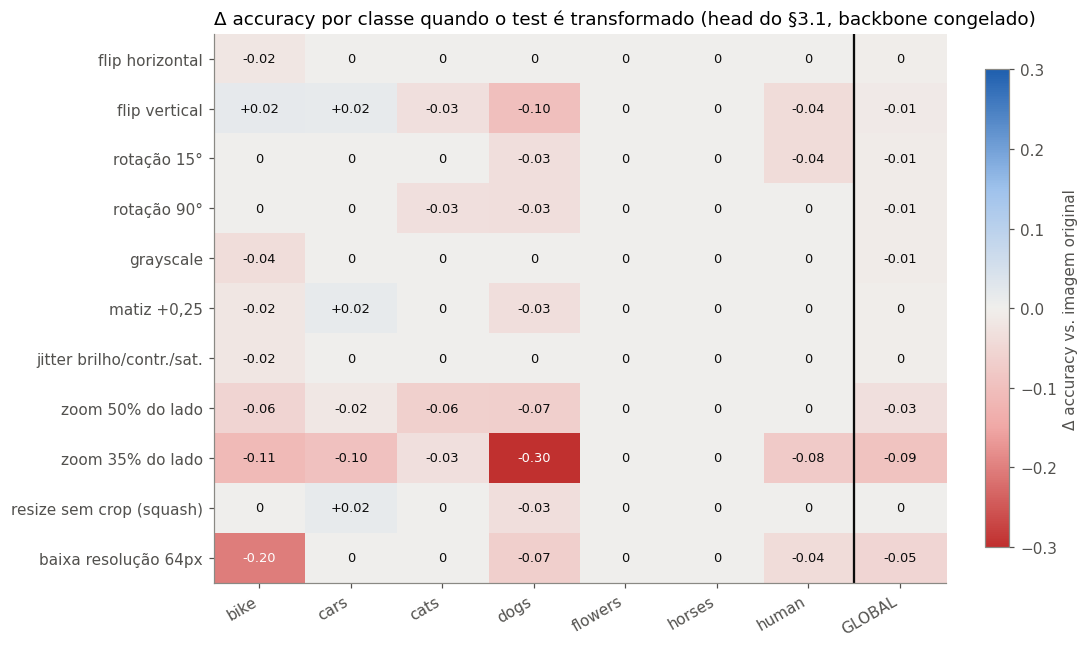

In [18]:
d = delta.drop(index="original")
lim = max(0.05, float(np.abs(d.values).max()))
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(d.values, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
for i in range(d.shape[0]):
    for j in range(d.shape[1]):
        v = d.values[i, j]
        ax.text(j, i, f"{v:+.2f}" if abs(v) >= 0.005 else "0", ha="center", va="center", fontsize=8.5,
                color="white" if abs(v) > 0.6 * lim else "#0b0b0b")
ax.set_xticks(range(d.shape[1]), d.columns, rotation=30, ha="right"); ax.set_yticks(range(d.shape[0]), d.index)
ax.axvline(NC - 0.5, color="#0b0b0b", lw=1.5); ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.03, label="Δ accuracy vs. imagem original")
ax.set_title("Δ accuracy por classe quando o test é transformado (head do §3.1, backbone congelado)", loc="left")
plt.tight_layout(); plt.savefig(FIG_DIR / "sensibilidade_por_classe.png"); plt.show()

**Leitura da sensibilidade** (1 imagem = 0,38 p.p. no global e 2–4 p.p. numa classe; leia os padrões, não as casas
decimais):

- **Flip horizontal: inofensivo** (−0,004 global, 1 imagem). Fotos de objetos não têm lateralidade.
- **Flip vertical: distorce** `dogs` (−0,10, 3 cães → gato), `human` (−0,04) e `cats` (−0,03). Animais e pessoas de
  cabeça para baixo não existem no domínio.
- **Rotação:** 15° custa 1 imagem em `dogs` e outra em `human`; 90° custa 1 em `cats` e outra em `dogs`. As features
  do ImageNet não são invariantes à rotação, mas uma rotação leve quase não as afeta.
- **Cor: quase irrelevante para as features congeladas.** Grayscale, matiz +0,25 e jitter custam no máximo 2 imagens,
  todas em `bike → cars`. **`flowers` não perde nada nem em grayscale nem com a matiz deslocada**: a hipótese "flor =
  cor" é **refutada**, porque a forma radial das pétalas basta.
- **Zoom: a transformação mais destrutiva.** Com 50% do lado, a perda global é −0,031. Com **35% do lado (~12% da
  área)**, é **−0,092**:
  - `dogs` −0,30: um close de pelo ou focinho vira "gato";
  - `bike` −0,11 e `cars` −0,10: o recorte perde o veículo;
  - `human` −0,08.
  `flowers` e `horses` ficam intactos, porque o objeto ocupa a imagem toda.
- **Resize sem crop (squash): neutro** (0,000 global). Distorcer a proporção não prejudica, e mantém na imagem os objetos
  das bordas que o center crop corta.
- **Baixa resolução (64 px): `bike` −0,20** (9 bicicletas → `cars`). Raios e quadro finos desaparecem, e o que sobra é
  uma cena de rua genérica. As imagens degradadas **não** são puxadas para `flowers`, a classe de origem em 128 px.
  Logo, **não há atalho "imagem borrada = flor"**, e o viés de resolução da auditoria não está sendo explorado.

### 3.2.b Normalização: estatísticas do ImageNet vs. nenhuma vs. do próprio dataset

ImageNet  média (0.485, 0.456, 0.406) desvio (0.229, 0.224, 0.225)
dataset   média [0.485, 0.453, 0.396] desvio [0.257, 0.246, 0.254]


,acc test (3 seeds),F1 macro test,val loss mín.,train loss ep 5,norma média das features
normalização,,,,,
ImageNet (padrão dos pesos),0.9924 ± 0.0000,0.9951,0.0283,0.0918,12.1979
"sem normalização ([0,1])",0.9860 ± 0.0018,0.9885,0.0249,0.0916,12.2284
média/desvio do dataset,0.9924 ± 0.0000,0.9951,0.0295,0.0917,12.1804


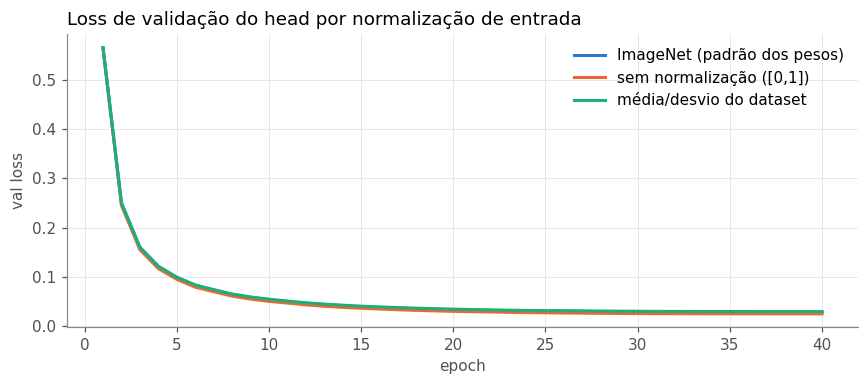

In [19]:
t0 = time.time()
# média/desvio por canal no TREINO (crop 224), calculados em uma amostra de 400 imagens
smp = np.random.default_rng(SEED).choice(tr, 400, replace=False)
px = torch.stack([T.ToTensor()(TF.center_crop(IMGS[k], 224)) for k in smp])
DS_MEAN, DS_STD = px.mean((0, 2, 3)).tolist(), px.std((0, 2, 3)).tolist()
del px
print("ImageNet  média", MEAN, "desvio", STD)
print("dataset   média", [round(v, 3) for v in DS_MEAN], "desvio", [round(v, 3) for v in DS_STD])

NORMS = {"ImageNet (padrão dos pesos)": EVAL_TF,
         "sem normalização ([0,1])": T.Compose([T.CenterCrop(224), T.ToTensor()]),
         "média/desvio do dataset": T.Compose([T.CenterCrop(224), T.ToTensor(), T.Normalize(DS_MEAN, DS_STD)])}
norm_rows, norm_hist = [], {}
for name, tf in NORMS.items():
    Fs = FEAT if name.startswith("ImageNet") else {s: extract(backbone, ids, tf)
                                                   for s, ids in [("train", tr), ("val", va), ("test", te)]}
    accs, f1s = [], []
    for s in [42, 1, 2]:
        h, hh, _ = train_head(Fs["train"], Y["train"], Fs["val"], Y["val"], seed=s)
        mm = metrics(Y["test"].numpy(), predict(h, Fs["test"]))
        accs.append(mm["accuracy"]); f1s.append(mm["f1_macro"])
        if s == 42:
            norm_hist[name] = hh
    norm_rows.append({"normalização": name, "acc test (3 seeds)": f"{np.mean(accs):.4f} ± {np.std(accs):.4f}",
                      "F1 macro test": f"{np.mean(f1s):.4f}", "val loss mín.": norm_hist[name].val_loss.min(),
                      "train loss ep 5": norm_hist[name].train_loss.iloc[4],
                      "norma média das features": Fs["test"].norm(dim=1).mean().item()})
norm_tab = pd.DataFrame(norm_rows).set_index("normalização")
display(norm_tab.round(4))
RESULTS["normalizacao"] = norm_tab.reset_index().to_dict(orient="records")

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, (name, hh) in enumerate(norm_hist.items()):
    ax.plot(hh.epoch, hh.val_loss, lw=2, color=PALETTE[i], label=name)
ax.set_xlabel("epoch"); ax.set_ylabel("val loss"); ax.legend(frameon=False)
ax.set_title("Loss de validação do head por normalização de entrada", loc="left")
plt.tight_layout(); plt.savefig(FIG_DIR / "normalizacao.png"); plt.show()
TIMES["3_2b_normalizacao"] = time.time() - t0

**Leitura.** A média e o desvio deste dataset (0,485 / 0,453 / 0,396) são praticamente os do ImageNet, porque são fotos
naturais. Por isso, usar as estatísticas do dataset dá **exatamente** o mesmo resultado (0,9924). Remover a
normalização custa **−0,6 p.p.** (0,9860 ± 0,0018, ou seja, 1–2 erros a mais conforme a seed) e o F1 macro cai para
0,989. É uma perda pequena, mas real, e é a única variante em que as seeds discordam: sem
normalização, o head não chega à mesma solução em 40 epochs. A explicação está na arquitetura:

- a `conv1` é linear, então uma entrada sem normalização equivale a um deslocamento e uma escala fixos por canal;
- a `bn1` congelada usa as médias móveis do ImageNet e não corrige esse deslocamento;
- as ativações saem da distribuição vista no pré-treino, e as camadas profundas absorvem só parte disso.

A val loss mínima sem normalização é até menor (0,025 contra 0,028), mas a accuracy de test é pior: com o problema no
teto, a loss de validação não discrimina bem as variantes.

**Conclusão:** usar a média e o desvio **do pré-treinamento** (ImageNet), que é a convenção sob a qual os pesos e as
estatísticas de BatchNorm foram aprendidos. Não é uma augmentation, é uma condição de correção, e não prejudica nenhuma
classe. As estatísticas do próprio dataset só fariam diferença num domínio distante (raio-X, satélite). Mesmo nesse
caso, com o backbone **congelado** deve-se manter as do pré-treino, porque as médias móveis de BN não serão
reestimadas.

### 3.2.c Augmentation no treino do head (backbone ainda congelado)

Com o backbone congelado, a augmentation entra assim: para cada imagem de treino gero **K = 3 vistas aleatórias**,
extraio as features de cada vista e treino o head em original + vistas (4 × 1.219 exemplos). As famílias seguem o
enunciado:

| Família | Transformações (no treino) |
|---|---|
| geométrica | flip horizontal (p=0,5) + rotação ±10° + recorte aleatório 224 dentro de 256 (translação) |
| cor | color jitter (brilho/contraste/saturação 0,4; matiz 0,1) + grayscale aleatório (p=0,2) |
| escala | `RandomResizedCrop(224, scale=(0,25; 1))`: zoom e recorte aleatórios (multi-scale) |
| combinada | flip H + rotação ±10° + `RandomResizedCrop(scale=(0,5; 1))` + jitter leve (0,2; matiz 0,02) + grayscale p=0,1 |

Avaliação: accuracy no test limpo (3 seeds do head) e **robustez**, a accuracy média no test sob as 11
transformações do §3.2.a.

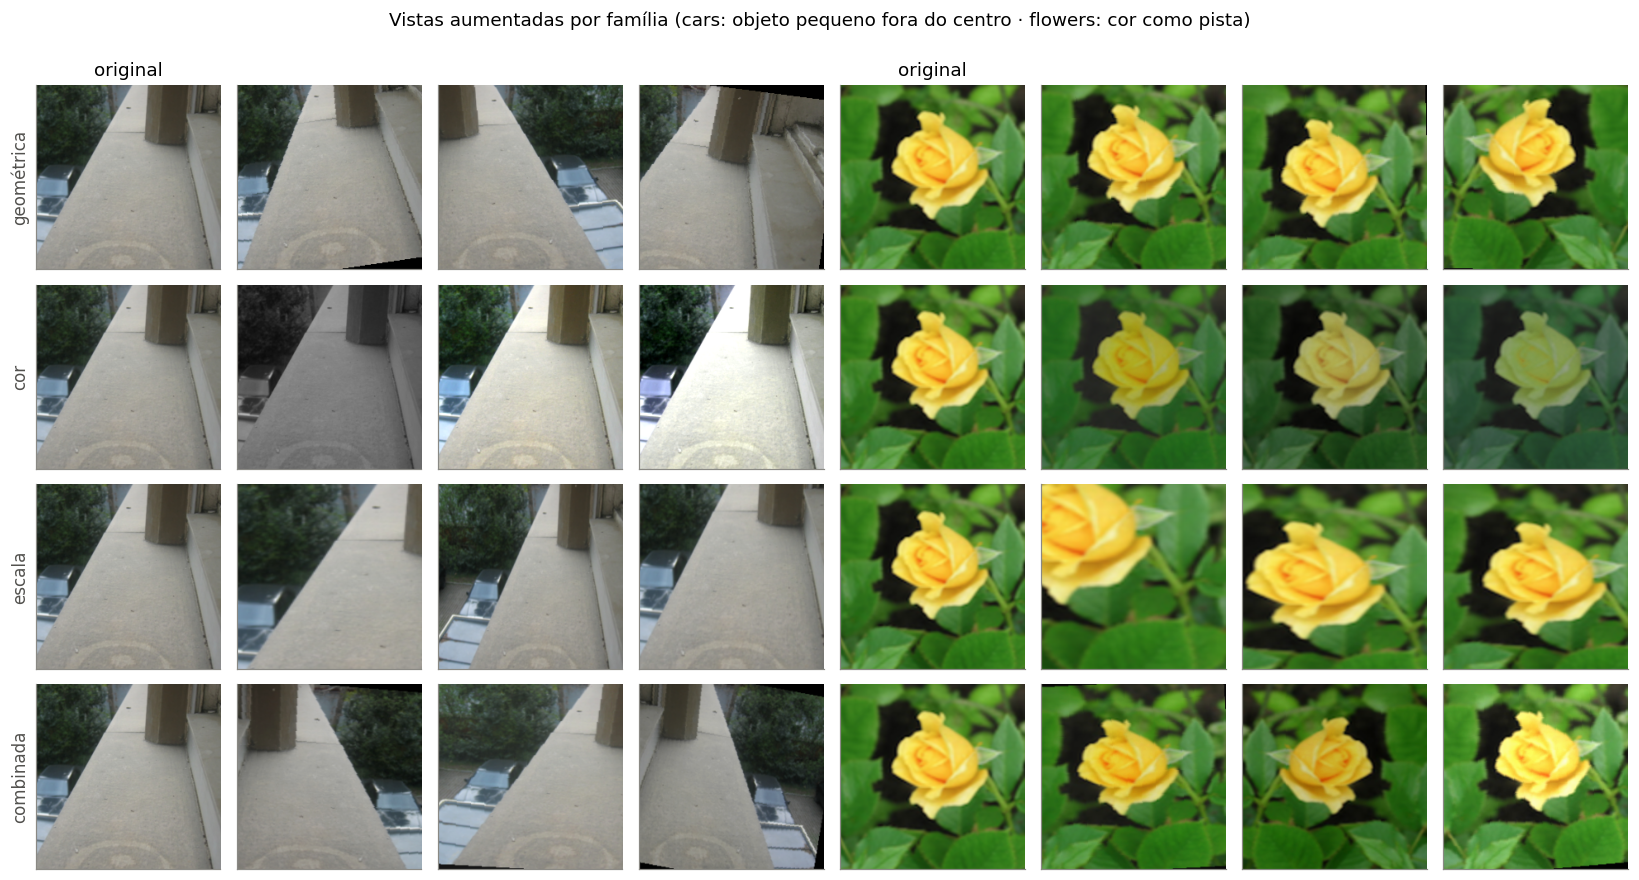

geométrica: (3657, 2048)  (18s)
cor: (3657, 2048)  (55s)
escala: (3657, 2048)  (72s)
combinada: (3657, 2048)  (117s)


In [20]:
t0 = time.time()
K_VIEWS = 3
AUG = {
    "geométrica": T.Compose([T.RandomHorizontalFlip(), T.RandomRotation(10), T.RandomCrop(224),
                             T.ToTensor(), T.Normalize(MEAN, STD)]),
    "cor": T.Compose([T.ColorJitter(0.4, 0.4, 0.4, 0.1), T.RandomGrayscale(0.2), T.CenterCrop(224),
                      T.ToTensor(), T.Normalize(MEAN, STD)]),
    "escala": T.Compose([T.RandomResizedCrop(224, scale=(0.25, 1.0)), T.ToTensor(), T.Normalize(MEAN, STD)]),
    "combinada": T.Compose([T.RandomHorizontalFlip(), T.RandomRotation(10), T.RandomResizedCrop(224, scale=(0.5, 1.0)),
                            T.ColorJitter(0.2, 0.2, 0.2, 0.02), T.RandomGrayscale(0.1),
                            T.ToTensor(), T.Normalize(MEAN, STD)]),
}

# exemplos visuais das vistas aumentadas (mesma imagem, uma linha por família)
demo = [tr[np.where(y[tr] == CLASSES.index("cars"))[0][3]], tr[np.where(y[tr] == CLASSES.index("flowers"))[0][5]]]
inv = lambda t: (t * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1).permute(1, 2, 0)
fig, axes = plt.subplots(len(AUG), 2 * 4, figsize=(15, 8))
torch.manual_seed(SEED)
for r, (name, tf) in enumerate(AUG.items()):
    for d_, k in enumerate(demo):
        axes[r, 4 * d_].imshow(inv(EVAL_TF(IMGS[k])))
        for v in range(1, 4):
            axes[r, 4 * d_ + v].imshow(inv(tf(IMGS[k])))
    axes[r, 0].set_ylabel(name, fontsize=11)
for a in axes.ravel():
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
axes[0, 0].set_title("original"); axes[0, 4].set_title("original")
plt.suptitle("Vistas aumentadas por família (cars: objeto pequeno fora do centro · flowers: cor como pista)", y=1.0)
plt.tight_layout(); plt.savefig(FIG_DIR / "augment_exemplos.png"); plt.show()

FEAT_AUG = {}
for name, tf in AUG.items():
    FEAT_AUG[name] = torch.cat([extract(backbone, tr, tf, seed=SEED + v) for v in range(K_VIEWS)])
    print(f"{name}: {tuple(FEAT_AUG[name].shape)}  ({time.time() - t0:.0f}s)")
TIMES["3_2c_extracao_aug"] = time.time() - t0

In [21]:
t0 = time.time()
pert_names = [k for k in PERTURB if k != "original"]
aug_rows, aug_cls, aug_pert = [], {}, {}
for name in ["sem augmentation", *AUG]:
    if name == "sem augmentation":
        Ftr_a, ytr_a = FEAT["train"], Y["train"]
    else:
        Ftr_a = torch.cat([FEAT["train"], FEAT_AUG[name]]); ytr_a = Y["train"].repeat(K_VIEWS + 1)
    accs, robs, cls_acc, pert_acc = [], [], [], []
    for s in [42, 1, 2]:
        h, _, _ = train_head(Ftr_a, ytr_a, FEAT["val"], Y["val"], seed=s)
        mm = metrics(yt, predict(h, FEAT["test"]))
        pa = {k: (predict(h, FEAT_PERT[k]).argmax(1) == yt).mean() for k in pert_names}
        accs.append(mm["accuracy"]); robs.append(np.mean(list(pa.values())))
        cls_acc.append(list(mm["acc_por_classe"].values())); pert_acc.append(list(pa.values()))
    aug_cls[name] = np.mean(cls_acc, 0); aug_pert[name] = np.mean(pert_acc, 0)
    aug_rows.append({"augmentation": name, "acc test limpo": np.mean(accs), "± (3 seeds)": np.std(accs),
                     "acc média test transformado": np.mean(robs), "± (3 seeds) ": np.std(robs)})
aug_tab = pd.DataFrame(aug_rows).set_index("augmentation")
aug_cls = pd.DataFrame(aug_cls, index=CLASSES).T
aug_pert = pd.DataFrame(aug_pert, index=pert_names).T
display(aug_tab.round(4))
print("accuracy por classe no test limpo (média 3 seeds):"); display(aug_cls.round(3))
print("accuracy no test transformado, por transformação (média 3 seeds):"); display(aug_pert.round(3))
RESULTS["augmentation"] = {"resumo": aug_tab.round(4).to_dict(orient="index"),
                           "por_classe": aug_cls.round(4).to_dict(orient="index"),
                           "por_transformacao": aug_pert.round(4).to_dict(orient="index")}
TIMES["3_2c_treinos"] = time.time() - t0

,acc test limpo,± (3 seeds),acc média test transformado,± (3 seeds)
augmentation,,,,
sem augmentation,0.9924,0.0000,0.9721,0.0002
geométrica,0.9924,0.0000,0.9755,0.0003
cor,0.9898,0.0018,0.9717,0.0004
escala,0.9924,0.0000,0.9762,0.0002
combinada,0.9924,0.0000,0.9749,0.0004


accuracy por classe no test limpo (média 3 seeds):


,bike,cars,cats,dogs,flowers,horses,human
sem augmentation,0.981,0.984,1.0,1.0,1.0,1.0,1.0
geométrica,0.981,0.984,1.0,1.0,1.0,1.0,1.0
cor,0.969,0.984,1.0,1.0,1.0,1.0,1.0
escala,0.981,0.984,1.0,1.0,1.0,1.0,1.0
combinada,0.981,0.984,1.0,1.0,1.0,1.0,1.0


accuracy no test transformado, por transformação (média 3 seeds):


,flip horizontal,flip vertical,rotação 15°,rotação 90°,grayscale,"matiz +0,25",jitter brilho/contr./sat.,zoom 50% do lado,zoom 35% do lado,resize sem crop (squash),baixa resolução 64px
sem augmentation,0.989,0.981,0.985,0.982,0.987,0.987,0.989,0.962,0.899,0.994,0.939
geométrica,0.992,0.981,0.992,0.977,0.989,0.990,0.996,0.968,0.905,0.992,0.948
cor,0.989,0.977,0.976,0.981,0.985,0.989,0.992,0.962,0.897,0.996,0.945
escala,0.991,0.978,0.982,0.983,0.995,0.992,0.992,0.973,0.912,0.996,0.941
combinada,0.991,0.981,0.981,0.981,0.991,0.989,0.992,0.961,0.906,1.000,0.952


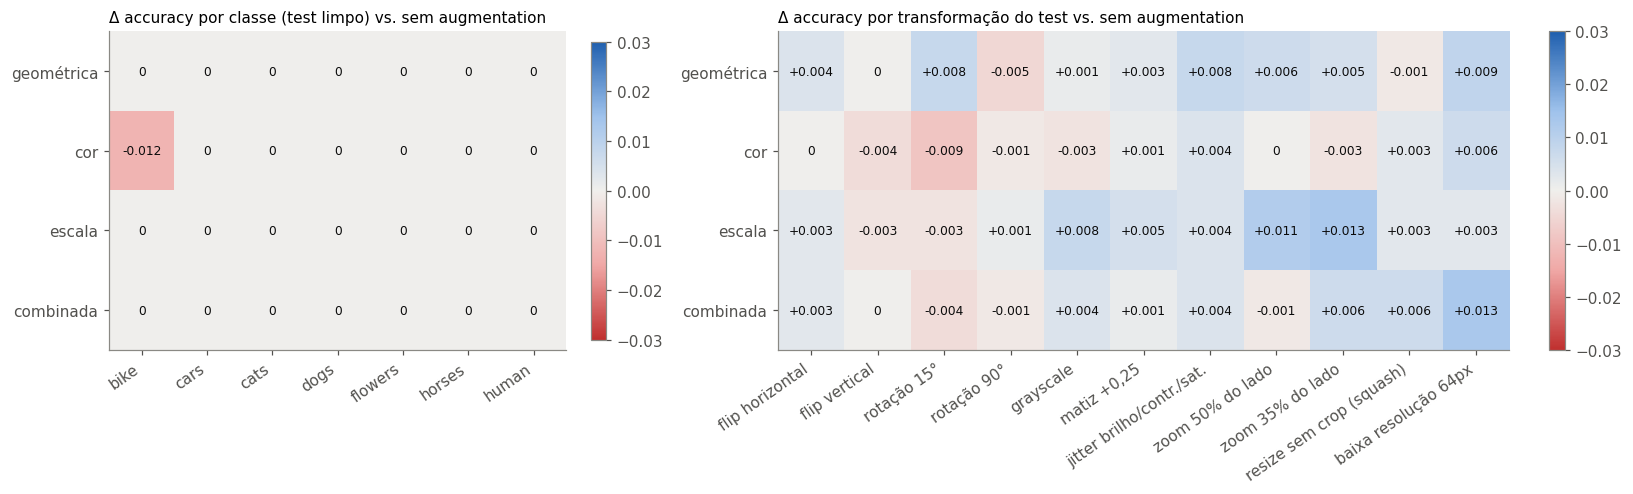

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1.6]})
dc = aug_cls - aug_cls.loc["sem augmentation"]
dp = aug_pert - aug_pert.loc["sem augmentation"]
for a, dd, title in [(ax[0], dc, "Δ accuracy por classe (test limpo)"),
                     (ax[1], dp, "Δ accuracy por transformação do test")]:
    dd = dd.drop(index="sem augmentation")
    lim = max(0.03, float(np.abs(dd.values).max()))
    im = a.imshow(dd.values, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
    for i in range(dd.shape[0]):
        for j in range(dd.shape[1]):
            v = dd.values[i, j]
            a.text(j, i, f"{v:+.3f}" if abs(v) >= 0.0005 else "0", ha="center", va="center", fontsize=8,
                   color="white" if abs(v) > 0.6 * lim else "#0b0b0b")
    a.set_xticks(range(dd.shape[1]), dd.columns, rotation=35, ha="right"); a.set_yticks(range(dd.shape[0]), dd.index)
    a.grid(False); a.set_title(title + " vs. sem augmentation", loc="left", fontsize=10)
    plt.colorbar(im, ax=a, fraction=0.03)
plt.tight_layout(); plt.savefig(FIG_DIR / "augment_resultados.png"); plt.show()

**Leitura.**

| Augmentation no treino do head | Accuracy test limpo | Accuracy média no test transformado | Maiores ganhos | Maior perda |
|---|---|---|---|---|
| sem augmentation | 0,9924 | 0,9721 | — | — |
| geométrica | 0,9924 | 0,9755 | baixa resolução +0,9 · rotação 15° +0,8 · jitter +0,8 p.p. | rotação 90° −0,5 p.p. |
| cor | **0,9898** (`bike` 0,969) | 0,9717 | baixa resolução +0,6 · jitter +0,4 p.p. | rotação 15° −0,9 p.p. |
| **escala** | 0,9924 | **0,9762** | **zoom 35% +1,3 · zoom 50% +1,2** · grayscale +0,8 p.p. | flip vertical −0,3 · rotação 15° −0,3 p.p. |
| combinada | 0,9924 | 0,9749 | **baixa resolução +1,3** · zoom 35% +0,6 · squash +0,6 p.p. | rotação 15° −0,4 p.p. |

- **No test limpo, nenhuma família melhora**: geométrica, escala e combinada mantêm 0,9924, com os mesmos 2 erros. O
  problema está no teto, e os dois erros são cenas ambíguas que nenhuma transformação de imagem resolve.
- **A família cor é a única que piora o test limpo**: `bike` cai de 0,981 para 0,969 (média de 3 seeds). É coerente com
  o §3.2.a, onde `bike` foi a classe mais sensível a grayscale e matiz (bike → cars). Com grayscale em p = 0,2 e matiz
  0,1, a cor deixa de ajudar a separar bicicletas de cenas de rua com carros.
- **A augmentation aparece na robustez.**
  - **Escala** tem a melhor média (+0,4 p.p.) e é a única que ataca a maior fragilidade do §3.2.a, o zoom agressivo
    (0,899 → 0,912 no zoom 35%; 0,962 → 0,973 no zoom 50%).
  - A **combinada** dá o maior ganho em baixa resolução (0,939 → 0,952) e acerta 100% no squash.
  - **Cor** sozinha não melhora a robustez média (−0,04 p.p.).
- **Os padrões se repetem entre execuções, as casas decimais não.** Numa execução anterior em CPU (outras vistas
  aleatórias), a combinada tinha ficado em primeiro (0,9769) e a escala tinha dado +2,5 p.p. no zoom 35%. Nas duas
  execuções valem as mesmas conclusões: o test limpo não melhora, escala melhora o zoom, a combinada melhora a baixa
  resolução, cor sozinha não ajuda e os ganhos ficam entre 1 e 2,5 p.p. Diferenças abaixo de ~1 p.p. entre famílias
  estão dentro dessa variação (1 imagem = 0,38 p.p.).
- **Por que os ganhos são pequenos:** com o backbone congelado, a augmentation só ensina o *head* a lidar com a
  distribuição das features de imagens transformadas. Ela **não torna as features invariantes**. Para isso, a
  augmentation precisa atuar *durante* o fine-tuning das camadas convolucionais (§4).

### Síntese do §3.2: o que eu testaria e para quais classes cada opção é benéfica ou perigosa

| Estratégia | Benéfica? | Evidência neste notebook | Por quê | Classes onde pode distorcer ou prejudicar |
|---|---|---|---|---|
| **Geométrica:** flip horizontal | **Sim** | −0,004 no test espelhado; sem efeito no limpo | Objetos naturais não têm lateralidade; dobra a variedade de poses de graça | Nenhuma. (Só seria um problema com texto ou placas, que não definem nenhuma classe) |
| **Geométrica:** rotação leve (±10°) | **Sim, leve** | 15° custa 1 imagem em `dogs` e outra em `human`; a família geométrica dá +0,8 p.p. em rotação 15° | Simula a câmera inclinada das fotos amadoras de pets | `human` e `dogs` (pose vertical característica); os cantos pretos da rotação viram artefato. Preferir preenchimento por reflexão |
| **Geométrica:** recorte aleatório (translação) | **Com cautela** | 5 imagens `bike` já perdem a bicicleta no center crop (auditoria) | Desloca o objeto e reduz a dependência da posição central | **`bike` e `cars`**: o objeto costuma estar na borda da cena do Graz-02; o recorte pode gerar um exemplo com rótulo "errado" |
| **Geométrica:** flip vertical, rotação 90° | **Não** | flip V: `dogs` −0,10, `human` −0,04 | Orientações que não ocorrem no domínio | `dogs`, `cats`, `human`, `horses` |
| **Cor:** color jitter (brilho/contraste/saturação) | **Sim, leve** | Jitter leve (na combinada) mantém o limpo e dá +0,4 p.p. no test com jitter; o jitter forte da família cor custou 1 imagem de `bike` no limpo | Fotos de fontes e câmeras diferentes; evita usar a "paleta da fonte" como pista | **`bike`**: a classe mais sensível à cor. Matiz forte (> 0,05) também cria cores irreais para `horses` (alazão = 71% *sorrel*) e `flowers`, embora `flowers` tenha tolerado |
| **Cor:** grayscale aleatório (p≈0,1) | **Sim, com p baixo** | Na combinada (p = 0,1), grayscale 0,987 → 0,991 sem custo no limpo; com p = 0,2 (família cor), `bike` piora | `human` tem **10,4%** de fotos P&B/sépia contra ≤ 4,3% nas outras classes: o grayscale **remove o atalho espúrio "P&B ⇒ human"** | `bike` (−0,037 no test em grayscale, bike → cars). `flowers` não foi afetada, contra a intuição |
| **Escala:** `RandomResizedCrop` / multi-scale | **Sim, com `scale` mínimo ≥ 0,35–0,5** | Melhor robustez média (+0,4 p.p.): zoom 35% +1,3, zoom 50% +1,2 p.p. | Ataca a maior fragilidade medida (objetos em escalas diferentes) | O padrão `scale=(0,08; 1)` é perigoso para **`cars` e `bike`** (veículo pequeno cortado fora) e **`dogs`** (close de pelo vira "gato", −0,30 no zoom 35%). `flowers` e `horses` são imunes |
| **Normalização:** média/desvio do ImageNet | **Obrigatória** | Sem ela −0,6 p.p.; estatísticas do dataset = mesmo resultado | É a convenção dos pesos e das médias móveis de BN congeladas | Nenhuma: é uma correção, não uma augmentation |

**Proposta que eu levaria ao próximo experimento (fine-tuning parcial, §4):**

- **Treino:** `RandomResizedCrop(224, scale=(0,5; 1))` + `RandomHorizontalFlip` + `RandomRotation(10, fill=reflexão)`
  + `ColorJitter(0,2; 0,2; 0,2; 0,02)` + `RandomGrayscale(0,1)` + `Normalize(ImageNet)`;
- **Avaliação:** `Resize((224, 224))` sem crop. O squash foi neutro e evita cortar bicicletas e carros na borda;
- **Nunca:** flip vertical, rotações grandes e cor forte (matiz > 0,05, grayscale > 0,1), por causa de `bike`.

No test limpo o ganho esperado é ~0, porque o problema já está no teto. O ganho está em **robustez a escala e
resolução**, que é o que muda quando o modelo sai deste dataset.

## 4. Feature extraction vs. fine-tuning

Para ancorar a discussão, comparo também a EfficientNet-B0 no mesmo protocolo de feature extraction (backbone
congelado, head linear, 3 seeds).

In [23]:
t0 = time.time()
W_B0 = models.EfficientNet_B0_Weights.IMAGENET1K_V1
b0 = models.efficientnet_b0(weights=W_B0)
for p in b0.parameters():
    p.requires_grad = False
b0.classifier[-1] = nn.Linear(b0.classifier[-1].in_features, NC)   # novo head (mesma lógica da ResNet)
b0_backbone = nn.Sequential(b0.features, b0.avgpool, nn.Flatten()).to(device).eval()
tb = time.time()
FEAT_B0 = {s: extract(b0_backbone, ids, EVAL_TF) for s, ids in [("train", tr), ("val", va), ("test", te)]}
t_b0 = time.time() - tb
accs, f1s = [], []
for s in [42, 1, 2]:
    h, _, _ = train_head(FEAT_B0["train"], Y["train"], FEAT_B0["val"], Y["val"], seed=s)
    mm = metrics(yt, predict(h, FEAT_B0["test"])); accs.append(mm["accuracy"]); f1s.append(mm["f1_macro"])
cmp_tab = pd.DataFrame({
    "ResNet-50": {"params backbone (M)": model_tab.loc["ResNet-50", "parâmetros (M)"], "dim. features": 2048,
                  "params treináveis (head)": 2048 * NC + NC, "tempo de extração (s)": TIMES["3_1_extracao_r50"],
                  "acc test (3 seeds)": seed_df.accuracy.iloc[:3].mean(), "F1 macro test": seed_df.f1_macro.iloc[:3].mean()},
    "EfficientNet-B0": {"params backbone (M)": model_tab.loc["EfficientNet-B0", "parâmetros (M)"], "dim. features": 1280,
                        "params treináveis (head)": 1280 * NC + NC, "tempo de extração (s)": t_b0,
                        "acc test (3 seeds)": np.mean(accs), "F1 macro test": np.mean(f1s)}}).T
display(cmp_tab.round(4))
RESULTS["comparacao_backbones"] = cmp_tab.round(4).to_dict(orient="index")
TIMES["4_effnet"] = time.time() - t0

,params backbone (M),dim. features,params treináveis (head),tempo de extração (s),acc test (3 seeds),F1 macro test
ResNet-50,25.56,2048.0,14343.0,7.7942,0.9924,0.9951
EfficientNet-B0,5.29,1280.0,8967.0,4.7659,0.9847,0.9841


**EfficientNet-B0 vs. ResNet-50 (mesmo protocolo).** A B0 tem vazão 2,6× maior na T4 (751 vs. 286 imagens/s) e um
head 37% menor,
mas erra 4 imagens contra 2 (0,9847 vs. 0,9924; F1 macro 0,984 vs. 0,995). É uma diferença pequena, mas na direção
esperada: o top-1 no ImageNet tende a prever a qualidade das features transferidas (Kornblith et al., 2019). Como a T4
não é gargalo para um backbone congelado, a ResNet-50 é a escolha certa aqui. A B0 seria preferível em edge ou mobile,
ou num fine-tuning completo com pouca memória.

**Quando usar cada estratégia.** A decisão depende de dois eixos: **tamanho do dataset** e **distância do domínio**
para o pré-treino.

| | **Domínio próximo do ImageNet** (objetos, animais, cenas) | **Domínio distante** (raio-X, satélite, microscopia, documentos) |
|---|---|---|
| **Dataset pequeno** (centenas a poucos milhares) | **Feature extraction** ← *este caso* | Fine-tuning **parcial** (últimos blocos) com lr baixo e augmentation forte, ou um backbone pré-treinado no domínio |
| **Dataset grande** (dezenas de milhares ou mais) | Fine-tuning (parcial → completo): ganho modesto, mas real | **Fine-tuning completo** (ou treino do zero, se for muito grande) |

**Por que feature extraction aqui, com base nos dados:**

1. **Tamanho:** 1.219 imagens de treino contra **23,5 M** parâmetros no backbone. O fine-tuning completo tem ~19 mil
   parâmetros por imagem e alto risco de overfitting; o head linear tem ~12 por imagem e é convexo (§3.1).
2. **Domínio:** as 7 classes estão no vocabulário do ImageNet (decodificação do §3.1) e o t-SNE separa todas **sem
   treino**. As features já são as certas, e reaprendê-las não tem o que acrescentar.
3. **Espaço de ganho:** 0,992 no test, com 2 erros que são cenas ambíguas. O fine-tuning não tem como provar melhoria
   com 262 imagens de test, onde 1 imagem vale 0,38 p.p.
4. **Custo:** uma passada de inferência e ~1 s de treino do head; o fine-tuning exigiria backward por 25 M parâmetros a
   cada epoch.

**Quando eu passaria para fine-tuning neste mesmo problema:**

- se a **robustez** importasse (fotos de outras câmeras, zoom e resolução variados). O §3.2.c mostrou que, com backbone
  congelado, a augmentation dá só +1 a +2,5 p.p. de robustez, porque não muda as features;
- se as classes ficassem **finas** (raças de cães, modelos de carro) ou se surgissem classes **fora do ImageNet** (o
  `human` já mostra o limite: não há classe "pessoa" no ImageNet);
- se o dataset crescesse para alguns milhares de imagens por classe.

**Receita:**

- descongelar progressivamente `layer4` e depois `layer3`;
- learning rates discriminativos (~1e-4 no backbone, 1e-3 no head);
- BatchNorm em `eval()` enquanto o batch for pequeno;
- early stopping pela val loss;
- as augmentations da síntese do §3.2.

Contraste com a A4 (raio-X de tórax): lá o domínio é distante do ImageNet e o fine-tuning completo de uma ResNet-18
pré-treinada foi peça central do protocolo corrigido que levou a recall COVID-19 de 0,30 para 0,79. Mesmo método de
transfer learning, decisões opostas, porque os dois eixos da tabela são opostos.

## 5. Conclusões e limitações

- **Feature extraction resolve este problema.** ResNet-50 congelada, `fc` → `Linear(2048, 7)` (14.343 parâmetros
  treináveis, 0,06% do modelo), um treino de 40 epochs: **accuracy de test 0,992**, cinco classes com 1,000 e
  `bike`/`cars` com 0,98. O resultado é idêntico em 5 seeds (problema convexo), não há overfitting nas curvas e tudo
  roda em ~6 min na T4.
- **Auditar o dataset foi tão importante quanto o modelo.** Havia 39 duplicatas exatas, 22 near-duplicates e uma cópia
  inteira do dataset em `data/data`; cada classe vem de uma fonte com formato e resolução próprios; 10% de `human` é P&B;
  e o center crop corta a bicicleta de algumas imagens `bike`.
- **Augmentation, com evidência:**
  - flip horizontal é seguro;
  - escala é a mais útil para robustez, mas com `scale` mínimo alto, por causa de `cars`, `bike` e `dogs`;
  - grayscale com p baixo remove um atalho de `human`; cor forte prejudica `bike`;
  - flip vertical prejudica animais e pessoas;
  - a cor quase não importa para as features congeladas, nem para `flowers`;
  - a normalização ImageNet é obrigatória (−0,6 p.p. sem ela).
- **Com o backbone congelado, a augmentation melhora pouco** (+1 a +2,5 p.p. de robustez conforme a execução, zero
  no test limpo). Ela rende de verdade quando acompanha o fine-tuning das camadas convolucionais.

**Limitações:**

- o test tem 262 imagens (1 imagem = 0,38 p.p.) e o problema está no teto, então diferenças abaixo de ~1 p.p. entre
  variantes não são conclusivas;
- as vistas aleatórias da augmentation mudam entre ambientes (CPU/GPU, número de workers), e a ordem das famílias variou
  ~1 p.p. entre a execução local e a do Colab; as conclusões qualitativas se mantiveram;
- o dataset é "fácil" em parte **porque cada classe vem de uma fonte diferente**: o desempenho num conjunto com fontes
  misturadas seria menor, e isso não foi medido;
- o Graz-02 dá um único rótulo a cenas com vários objetos;
- não houve experimento de fine-tuning (a discussão do §4 é argumentada, não medida).

**Referências**

- He, K., Zhang, X., Ren, S. & Sun, J. (2016). Deep Residual Learning for Image Recognition. *CVPR*.
- Tan, M. & Le, Q. (2019). EfficientNet: Rethinking Model Scaling for CNNs. *ICML*.
- Deng, J. et al. (2009). ImageNet: A Large-Scale Hierarchical Image Database. *CVPR*.
- Wightman, R., Touvron, H. & Jégou, H. (2021). ResNet strikes back (receita dos pesos `IMAGENET1K_V2`). *arXiv:2110.00476*.
- Yosinski, J. et al. (2014). How transferable are features in deep neural networks? *NeurIPS*.
- Kornblith, S., Shlens, J. & Le, Q. (2019). Do Better ImageNet Models Transfer Better? *CVPR*.
- Shorten, C. & Khoshgoftaar, T. (2019). A survey on Image Data Augmentation for Deep Learning. *Journal of Big Data*.
- Geirhos, R. et al. (2020). Shortcut learning in deep neural networks. *Nature Machine Intelligence*.
- Opelt, A. et al. (2006). Generic object recognition with boosting (dataset Graz-02). *IEEE TPAMI*.
- van der Maaten, L. & Hinton, G. (2008). Visualizing Data using t-SNE. *JMLR*.
- Dataset: Sanagapati, P. *Images Dataset*. Kaggle: https://www.kaggle.com/datasets/pavansanagapati/images-dataset

## Uso de IA

Ferramenta de IA usada como apoio, conforme a política "Sinal Verde" da disciplina:
**Claude (Anthropic), modelo Claude Opus 5.5, via Claude Code**: estruturação do notebook, implementação de apoio
(auditoria do dataset, pipeline de feature extraction com cache, experimentos de sensibilidade/normalização/augmentation),
revisão de código e redação de apoio das análises.

Todo o código foi executado e validado pelo autor; as análises e conclusões foram verificadas contra os resultados
reais obtidos.

## Medições e exportação

Imprime tempo total, VRAM e RAM (para a tabela de requisitos), salva `results.json` e compacta `figures/`.

In [24]:
import psutil
TIMES["total"] = time.time() - T_START
RESULTS["tempos_s"] = {k: round(v, 1) for k, v in TIMES.items()}
RESULTS["device"] = torch.cuda.get_device_name(0) if device == "cuda" else "CPU"
RESULTS["vram_pico_gb"] = torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else None
RESULTS["ram_processo_gb"] = psutil.Process().memory_info().rss / 1e9
print(json.dumps({k: RESULTS[k] for k in ["device", "tempos_s", "vram_pico_gb", "ram_processo_gb"]}, indent=2))


def _clean(o):
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else float(o)
    return o


with open(FIG_DIR / "results.json", "w", encoding="utf-8") as f:
    json.dump(_clean(RESULTS), f, indent=2, ensure_ascii=False)
shutil.make_archive(str(ROOT / "figures"), "zip", FIG_DIR)
print("figuras + results.json em", ROOT / "figures.zip")
if IN_COLAB:
    from google.colab import files
    files.download(str(ROOT / "figures.zip"))

{
  "device": "Tesla T4",
  "tempos_s": {
    "1_dataset": 67.2,
    "3_1_extracao_r50": 7.8,
    "3_1_treino_head": 1.4,
    "3_1_tsne": 14.0,
    "3_2a_sensibilidade": 16.1,
    "3_2b_normalizacao": 26.8,
    "3_2c_extracao_aug": 116.6,
    "3_2c_treinos": 57.5,
    "4_effnet": 8.2,
    "total": 340.2
  },
  "vram_pico_gb": 0.864940544,
  "ram_processo_gb": 2.859278336
}
figuras + results.json em /content/figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>